In [ ]:

!pip -q install pandas numpy scikit-learn matplotlib seaborn joblib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (
    GroupShuffleSplit,
    StratifiedGroupKFold,
    cross_validate
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [ ]:

url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/parkinsons/"
    "parkinsons.data"
)

df = pd.read_csv(url)

df["participant_id"] = (
    df["name"].str.rsplit("_", n=1).str[0]
)

X = df.drop(
    columns=["name", "participant_id", "status"]
)
y = df["status"].astype(int)
groups = df["participant_id"]

print("Recordings:", len(df))
print("Participants:", groups.nunique())
print("Features:", X.shape[1])
print("\nClass distribution:")
print(y.value_counts())

Recordings: 195
Participants: 32
Features: 22

Class distribution:
status
1    147
0     48
Name: count, dtype: int64


In [ ]:
import pandas as pd
# Fixes your current NameError
from sklearn.model_selection import train_test_split

# Feature Selection
from sklearn.feature_selection import SelectKBest, f_classif

# Pipelines and Preprocessing
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Machine Learning Models
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC

# Feature Selection (fixes your current error)
from sklearn.feature_selection import SelectKBest, f_classif

# Pipelines and Preprocessing
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Machine Learning Models
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC

# Define your random state constant if you haven't already
RANDOM_STATE = 42


# One label per participant
participant_labels = (
    df.groupby("participant_id")["status"]
    .first()
)

# Split participants into training and testing sets
train_ids, test_ids = train_test_split(
    participant_labels.index,
    test_size=0.25,
    stratify=participant_labels.values,
    random_state=42
)

# Create masks
train_mask = groups.isin(train_ids)
test_mask = groups.isin(test_ids)

# Separate features
X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

# Separate labels
y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

# Separate participant IDs
groups_train = groups.loc[train_mask].copy()
groups_test = groups.loc[test_mask].copy()

# Ensure no participant appears in both sets
assert set(groups_train).isdisjoint(
    set(groups_test)
)

print("Training participants:",
      groups_train.nunique())

print("Testing participants:",
      groups_test.nunique())

print("\nTraining class counts:")
print(y_train.value_counts())

print("\nTesting class counts:")
print(y_test.value_counts())

Training participants: 24
Testing participants: 8

Training class counts:
status
1    110
0     36
Name: count, dtype: int64

Testing class counts:
status
1    37
0    12
Name: count, dtype: int64


In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif
models = {
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(
            strategy="median"
        )),
        ("selector", SelectKBest(
            score_func=f_classif
        )),
        ("model", RandomForestClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(
            strategy="median"
        )),
        ("scaler", StandardScaler()),
        ("selector", SelectKBest(
            score_func=f_classif
        )),
        ("model", SVC(
            kernel="rbf",
            class_weight="balanced",
            probability=True,
            random_state=RANDOM_STATE
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(
            strategy="median"
        )),
        ("selector", SelectKBest(
            score_func=f_classif
        )),
        ("model", HistGradientBoostingClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ])
}

param_grids = {
    "Random Forest": {
        "selector__k": [5, 10, 15, "all"],
        "model__n_estimators": [100, 200, 400],
        "model__max_depth": [2, 3, 4, 5, None],
        "model__min_samples_leaf": [1, 2, 4, 6],
        "model__max_features": ["sqrt", 0.7]
    },

    "SVM": {
        "selector__k": [5, 10, 15, "all"],
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__gamma": [
            "scale", 0.001, 0.01, 0.1, 1
        ]
    },

    "Gradient Boosting": {
        "selector__k": [5, 10, 15, "all"],
        "model__max_iter": [50, 100, 200],
        "model__learning_rate": [
            0.01, 0.03, 0.05, 0.1
        ],
        "model__max_leaf_nodes": [3, 5, 7],
        "model__min_samples_leaf": [5, 10, 15],
        "model__l2_regularization": [0, 1, 10]
    }
}

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# Fixes potential errors for Cross-Validation and Pandas DataFrames
from sklearn.model_selection import StratifiedGroupKFold
import pandas as pd

cv = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Materialize folds and check their class composition.
folds = list(cv.split(
    X_train, y_train, groups_train
))

for i, (tr, val) in enumerate(folds, start=1):
    train_classes = set(y_train.iloc[tr])
    val_classes = set(y_train.iloc[val])

    print(
        f"Fold {i}:",
        "Training classes:", train_classes,
        "Validation classes:", val_classes
    )

    if train_classes != {0, 1} or val_classes != {0, 1}:
        raise ValueError(
            "A fold lacks a class. Reduce the "
            "number of folds or revise the split."
        )

best_models = {}
tuning_results = []

for name, pipeline in models.items():

    print("\nTraining:", name)

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_grids[name],
        n_iter=20,
        scoring="balanced_accuracy",
        cv=folds,
        n_jobs=-1,
        random_state=RANDOM_STATE,
        refit=True,
        error_score="raise"
    )

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "CV Balanced Accuracy": search.best_score_,
        "Best Parameters": search.best_params_
    })

    print("Best CV score:", search.best_score_)
    print("Best parameters:", search.best_params_)

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df)

Fold 1: Training classes: {0, 1} Validation classes: {0, 1}
Fold 2: Training classes: {0, 1} Validation classes: {0, 1}
Fold 3: Training classes: {0, 1} Validation classes: {0, 1}
Fold 4: Training classes: {0, 1} Validation classes: {0, 1}

Training: Random Forest
Best CV score: 0.6987007168458781
Best parameters: {'selector__k': 5, 'model__n_estimators': 200, 'model__min_samples_leaf': 4, 'model__max_features': 0.7, 'model__max_depth': 4}

Training: SVM
Best CV score: 0.6947333050367855
Best parameters: {'selector__k': 'all', 'model__gamma': 0.01, 'model__C': 0.1}

Training: Gradient Boosting
Best CV score: 0.7037970430107527
Best parameters: {'selector__k': 5, 'model__min_samples_leaf': 10, 'model__max_leaf_nodes': 5, 'model__max_iter': 200, 'model__learning_rate': 0.03, 'model__l2_regularization': 1}


,Model,CV Balanced Accuracy,Best Parameters
0,Random Forest,0.698701,"{'selector__k': 5, 'model__n_estimators': 200,..."
1,SVM,0.694733,"{'selector__k': 'all', 'model__gamma': 0.01, '..."
2,Gradient Boosting,0.703797,"{'selector__k': 5, 'model__min_samples_leaf': ..."



 Random Forest
              precision    recall  f1-score   support

     Healthy       1.00      0.75      0.86        12
 Parkinson's       0.93      1.00      0.96        37

    accuracy                           0.94        49
   macro avg       0.96      0.88      0.91        49
weighted avg       0.94      0.94      0.94        49



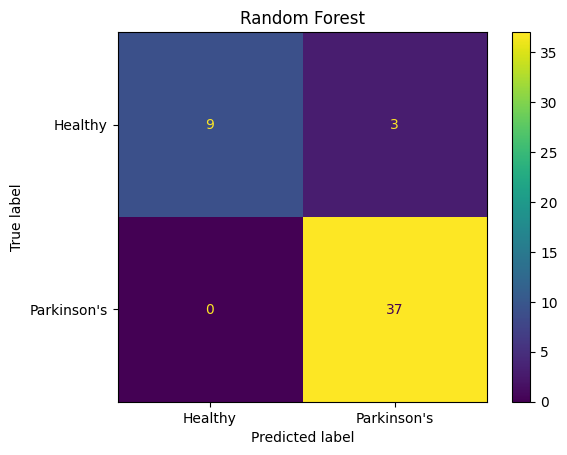


 SVM
              precision    recall  f1-score   support

     Healthy       1.00      0.83      0.91        12
 Parkinson's       0.95      1.00      0.97        37

    accuracy                           0.96        49
   macro avg       0.97      0.92      0.94        49
weighted avg       0.96      0.96      0.96        49



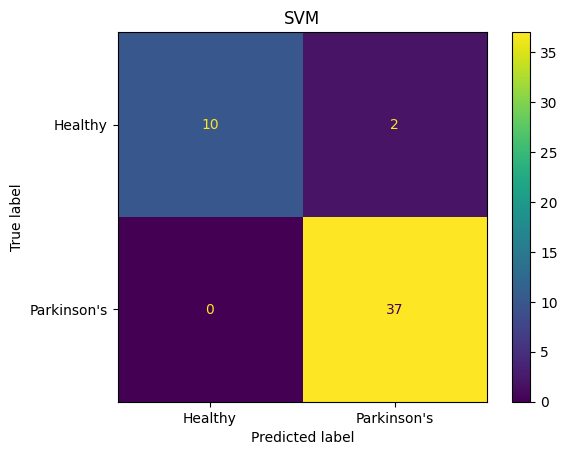


 Gradient Boosting
              precision    recall  f1-score   support

     Healthy       1.00      0.75      0.86        12
 Parkinson's       0.93      1.00      0.96        37

    accuracy                           0.94        49
   macro avg       0.96      0.88      0.91        49
weighted avg       0.94      0.94      0.94        49



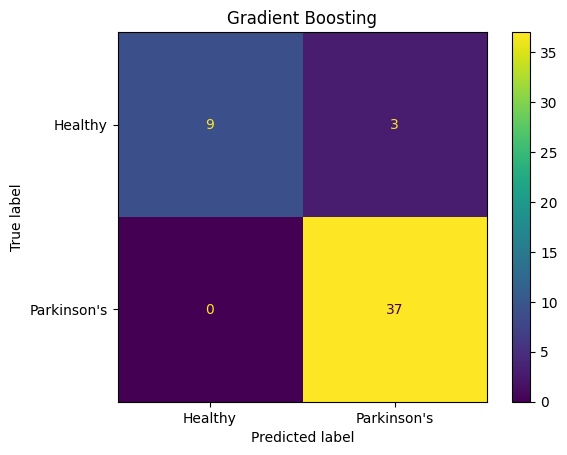

,Model,Accuracy,Balanced Accuracy,Sensitivity,Specificity
0,Random Forest,0.9388,0.8750,1.0,0.7500
1,SVM,0.9592,0.9167,1.0,0.8333
2,Gradient Boosting,0.9388,0.8750,1.0,0.7500


In [ ]:
# Evaluation Metrics (Fixes confusion_matrix, accuracy_score, balanced_accuracy_score, recall_score, and classification_report)
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Plotting Libraries (Fixes plt and handles the 'np' reference for missing values)
import matplotlib.pyplot as plt
import numpy as np

final_results = []

for name, model in best_models.items():

    predictions = model.predict(X_test)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(
            y_test, predictions
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Sensitivity": recall_score(
            y_test, predictions,
            pos_label=1,
            zero_division=0
        ),
        "Specificity": (
            tn / (tn + fp)
            if tn + fp else np.nan
        )
    }

    final_results.append(metrics)

    print("\n", name)
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["Healthy", "Parkinson's"],
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=["Healthy", "Parkinson's"]
    )
    plt.title(name)
    plt.show()

final_df = pd.DataFrame(final_results)

display(final_df.round(4))

In [ ]:

participant_results = []

for name, model in best_models.items():

    positive_index = list(
        model.classes_
    ).index(1)

    probabilities = model.predict_proba(
        X_test
    )[:, positive_index]

    patient_df = pd.DataFrame({
        "Participant": groups_test.to_numpy(),
        "Actual": y_test.to_numpy(),
        "Output": probabilities
    })

    patient_df = patient_df.groupby(
        "Participant"
    ).agg({
        "Actual": "first",
        "Output": "mean"
    })

    patient_df["Prediction"] = (
        patient_df["Output"] >= 0.5
    ).astype(int)

    print("\n", name)
    display(patient_df)

    accuracy = accuracy_score(
        patient_df["Actual"],
        patient_df["Prediction"]
    )

    balanced = balanced_accuracy_score(
        patient_df["Actual"],
        patient_df["Prediction"]
    )

    participant_results.append({
        "Model": name,
        "Participant Accuracy": accuracy,
        "Participant Balanced Accuracy": balanced
    })

display(
    pd.DataFrame(participant_results).round(4)
)


 Random Forest


,Actual,Output,Prediction
Participant,,,
phon_R01_S05,1,1.000000,1
phon_R01_S16,1,0.995723,1
phon_R01_S17,0,0.065340,0
phon_R01_S18,1,0.855905,1
phon_R01_S21,1,0.955606,1
phon_R01_S33,1,0.948698,1
phon_R01_S37,1,0.947194,1
phon_R01_S49,0,0.656929,1



 SVM


,Actual,Output,Prediction
Participant,,,
phon_R01_S05,1,0.886398,1
phon_R01_S16,1,0.873503,1
phon_R01_S17,0,0.526690,1
phon_R01_S18,1,0.854934,1
phon_R01_S21,1,0.877108,1
phon_R01_S33,1,0.882537,1
phon_R01_S37,1,0.860582,1
phon_R01_S49,0,0.742416,1



 Gradient Boosting


,Actual,Output,Prediction
Participant,,,
phon_R01_S05,1,0.986474,1
phon_R01_S16,1,0.972801,1
phon_R01_S17,0,0.013514,0
phon_R01_S18,1,0.966568,1
phon_R01_S21,1,0.977839,1
phon_R01_S33,1,0.914220,1
phon_R01_S37,1,0.981040,1
phon_R01_S49,0,0.613046,1


,Model,Participant Accuracy,Participant Balanced Accuracy
0,Random Forest,0.875,0.75
1,SVM,0.750,0.50
2,Gradient Boosting,0.875,0.75


In [ ]:
print(best_models.keys())

dict_keys(['Random Forest', 'SVM', 'Gradient Boosting'])


In [ ]:
rf_model = best_models["Random Forest"]
gb_model = best_models["Gradient Boosting"]

rf_probability = rf_model.predict_proba(X_test)[:, 1]
gb_probability = gb_model.predict_proba(X_test)[:, 1]

print("Random Forest probabilities:")
print(rf_probability[:10])

print("\nGradient Boosting probabilities:")
print(gb_probability[:10])

Random Forest probabilities:
[1.         1.         1.         1.         1.         1.
 0.99260332 0.99651899 1.         0.99623288]

Gradient Boosting probabilities:
[0.98829871 0.98992591 0.98548822 0.98548822 0.98548822 0.98415686
 0.98585712 0.98560334 0.98560334 0.96427367]


In [ ]:
RF_WEIGHT = 0.5
GB_WEIGHT = 0.5

ensemble_probability = (
    RF_WEIGHT * rf_probability
    + GB_WEIGHT * gb_probability
)

ensemble_prediction = (
    ensemble_probability >= 0.5
).astype(int)

print("First 10 ensemble probabilities:")

for probability, prediction in zip(
    ensemble_probability[:10],
    ensemble_prediction[:10]
):
    print(
    f"{'Parkinson\'s' if prediction == 1 else 'Healthy'}"
)


First 10 ensemble probabilities:
Parkinson's
Parkinson's
Parkinson's
Parkinson's
Parkinson's
Parkinson's
Parkinson's
Parkinson's
Parkinson's
Parkinson's


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

accuracy = accuracy_score(
    y_test,
    ensemble_prediction
)

balanced_accuracy = balanced_accuracy_score(
    y_test,
    ensemble_prediction
)

roc_auc = roc_auc_score(
    y_test,
    ensemble_probability
)

print("=" * 50)
print("ENSEMBLE RESULTS")
print("=" * 50)

print(
    f"Accuracy:           {accuracy * 100:.2f}%"
)

print(
    f"Balanced Accuracy:  {balanced_accuracy * 100:.2f}%"
)

print(
    f"ROC-AUC:            {roc_auc:.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        ensemble_prediction,
        labels=[0, 1],
        target_names=[
            "Healthy",
            "Parkinson's"
        ],
        zero_division=0
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_test,
        ensemble_prediction,
        labels=[0, 1]
    )
)

ENSEMBLE RESULTS
Accuracy:           93.88%
Balanced Accuracy:  87.50%
ROC-AUC:            0.9459

Classification Report:
              precision    recall  f1-score   support

     Healthy       1.00      0.75      0.86        12
 Parkinson's       0.93      1.00      0.96        37

    accuracy                           0.94        49
   macro avg       0.96      0.88      0.91        49
weighted avg       0.94      0.94      0.94        49


Confusion Matrix:
[[ 9  3]
 [ 0 37]]


In [ ]:
weight_results = []

for rf_weight in np.arange(0.0, 1.01, 0.05):

    gb_weight = 1.0 - rf_weight

    probability = (
        rf_weight * rf_probability
        + gb_weight * gb_probability
    )

    prediction = (
        probability >= 0.5
    ).astype(int)

    accuracy = accuracy_score(
        y_test,
        prediction
    )

    balanced = balanced_accuracy_score(
        y_test,
        prediction
    )

    weight_results.append({
        "RF Weight": rf_weight,
        "GB Weight": gb_weight,
        "Accuracy": accuracy,
        "Balanced Accuracy": balanced
    })

weight_df = pd.DataFrame(weight_results)

display(
    weight_df.sort_values(
        "Balanced Accuracy",
        ascending=False
    ).head(10)
)

,RF Weight,GB Weight,Accuracy,Balanced Accuracy
0,0.00,1.00,0.938776,0.875
1,0.05,0.95,0.938776,0.875
2,0.10,0.90,0.938776,0.875
3,0.15,0.85,0.938776,0.875
4,0.20,0.80,0.938776,0.875
5,0.25,0.75,0.938776,0.875
6,0.30,0.70,0.938776,0.875
7,0.35,0.65,0.938776,0.875
8,0.40,0.60,0.938776,0.875
9,0.45,0.55,0.938776,0.875


In [ ]:
RF_WEIGHT = 0.5
GB_WEIGHT = 0.5

final_ensemble = {
    "random_forest": rf_model,
    "gradient_boosting": gb_model,
    "rf_weight": RF_WEIGHT,
    "gb_weight": GB_WEIGHT,
    "feature_names": X_train.columns.tolist(),
    "positive_class": 1,
    "negative_class": 0
}

joblib.dump(
    final_ensemble,
    "parkinsons_ensemble_model.pkl"
)

print(
    "Saved: parkinsons_ensemble_model.pkl"
)

Saved: parkinsons_ensemble_model.pkl


In [ ]:
import os
import json
import zipfile

# Save the individual models as well
joblib.dump(
    rf_model,
    "random_forest_model.pkl"
)

joblib.dump(
    gb_model,
    "gradient_boosting_model.pkl"
)

# Save model configuration
config = {
    "rf_weight": RF_WEIGHT,
    "gb_weight": GB_WEIGHT,
    "positive_class": 1,
    "positive_label": "Parkinson's",
    "negative_class": 0,
    "negative_label": "Healthy",
    "feature_count": len(X_train.columns),
    "dataset": "UCI Parkinson's Disease Classification"
}

with open(
    "model_config.json",
    "w"
) as f:
    json.dump(
        config,
        f,
        indent=4
    )

# Create ZIP
zip_name = "parkinsons_ai_models.zip"

with zipfile.ZipFile(
    zip_name,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    zipf.write(
        "parkinsons_ensemble_model.pkl"
    )

    zipf.write(
        "random_forest_model.pkl"
    )

    zipf.write(
        "gradient_boosting_model.pkl"
    )

    zipf.write(
        "model_config.json"
    )

print("Created:", zip_name)

#from google.colab import files

#files.download(zip_name)

Created: parkinsons_ai_models.zip


In [ ]:
import pandas as pd
# Fixes your current NameError
from sklearn.model_selection import train_test_split

# Feature Selection
from sklearn.feature_selection import SelectKBest, f_classif

# Pipelines and Preprocessing
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Machine Learning Models
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC

In [ ]:

from pathlib import Path

BASE_DIR = Path("/content/parkinsons_audio")
DATA_DIR = BASE_DIR / "dataset"
MODEL_DIR = BASE_DIR / "models"

DATA_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Audio project:", BASE_DIR)

Audio project: /content/parkinsons_audio


In [ ]:

import requests

ARTICLE_ID = 23849127
API_URL = f"https://api.figshare.com/v2/articles/{ARTICLE_ID}"

response = requests.get(API_URL, timeout=60)
response.raise_for_status()

article = response.json()

print("Dataset:", article["title"])
print("\nAvailable files:")

for file in article["files"]:
    print(
        file["name"],
        "-",
        round(file["size"] / 1024 / 1024, 2),
        "MB"
    )

for file in article["files"]:
    name = file["name"]
    lower_name = name.lower()

    # Download the voice archives.
    if (
        lower_name.endswith(".zip")
        and ("pd" in lower_name or "hc" in lower_name)
    ):
        destination = DATA_DIR / name

        if not destination.exists():
            print("Downloading:", name)

            with requests.get(
                file["download_url"],
                stream=True,
                timeout=120
            ) as download:
                download.raise_for_status()

                with open(destination, "wb") as output:
                    for chunk in download.iter_content(
                        chunk_size=1024 * 1024
                    ):
                        if chunk:
                            output.write(chunk)

print("\nDownload complete.")

Dataset: Voice Samples for Patients with Parkinson’s Disease and Healthy Controls

Available files:
Demographics_age_sex.xlsx - 0.12 MB
PD_AH.zip - 2.14 MB
HC_AH.zip - 1.91 MB
Downloading: PD_AH.zip
Downloading: HC_AH.zip

Download complete.


In [ ]:

import zipfile

for archive in DATA_DIR.glob("*.zip"):
    name = archive.name.upper()

    if name.startswith("HC"):
        label_folder = DATA_DIR / "healthy"
    elif name.startswith("PD"):
        label_folder = DATA_DIR / "parkinsons"
    else:
        print("Skipping unrecognized archive:", name)
        continue

    label_folder.mkdir(exist_ok=True)

    with zipfile.ZipFile(archive, "r") as zip_file:
        zip_file.extractall(label_folder)

    print("Extracted:", archive.name)

healthy_files = list(
    (DATA_DIR / "healthy").rglob("*.wav")
)

pd_files = list(
    (DATA_DIR / "parkinsons").rglob("*.wav")
)

print("Healthy recordings:", len(healthy_files))
print("Parkinson's recordings:", len(pd_files))

assert len(healthy_files) > 0, "No healthy WAV files found."
assert len(pd_files) > 0, "No Parkinson's WAV files found."

Extracted: PD_AH.zip
Extracted: HC_AH.zip
Healthy recordings: 41
Parkinson's recordings: 40


In [ ]:

import numpy as np
import librosa

SAMPLE_RATE = 16000
N_MFCC = 20

def extract_audio_features(file_path):
    # Load audio as mono at a consistent sample rate.
    audio, sr = librosa.load(
        str(file_path),
        sr=SAMPLE_RATE,
        mono=True
    )

    # Remove leading and trailing silence.
    audio, _ = librosa.effects.trim(
        audio,
        top_db=30
    )

    if len(audio) < sr:
        raise ValueError(
            "Recording is too short after silence removal."
        )

    features = {}

    def add_summary(name, values):
        values = np.asarray(values, dtype=float)
        finite = values[np.isfinite(values)]

        features[name + "_mean"] = (
            float(np.mean(finite))
            if len(finite) else np.nan
        )

        features[name + "_std"] = (
            float(np.std(finite))
            if len(finite) else np.nan
        )

    # MFCCs
    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=N_MFCC
    )

    for i in range(N_MFCC):
        add_summary(f"mfcc_{i + 1}", mfcc[i])

    # Changes in MFCCs over time.
    delta = librosa.feature.delta(mfcc)

    for i in range(N_MFCC):
        add_summary(f"delta_mfcc_{i + 1}", delta[i])

    # Energy and spectral characteristics.
    add_summary(
        "rms",
        librosa.feature.rms(y=audio)[0]
    )

    add_summary(
        "zero_crossing_rate",
        librosa.feature.zero_crossing_rate(y=audio)[0]
    )

    add_summary(
        "spectral_centroid",
        librosa.feature.spectral_centroid(
            y=audio, sr=sr
        )[0]
    )

    add_summary(
        "spectral_bandwidth",
        librosa.feature.spectral_bandwidth(
            y=audio, sr=sr
        )[0]
    )

    add_summary(
        "spectral_rolloff",
        librosa.feature.spectral_rolloff(
            y=audio, sr=sr
        )[0]
    )

    add_summary(
        "spectral_flatness",
        librosa.feature.spectral_flatness(
            y=audio
        )[0]
    )

    # Fundamental frequency (pitch).
    pitch, voiced_flag, _ = librosa.pyin(
        audio,
        sr=sr,
        fmin=65,
        fmax=600
    )

    add_summary("pitch", pitch)

    features["voiced_fraction"] = float(
        np.mean(voiced_flag)
    )

    return features

In [ ]:

import pandas as pd

records = []
errors = []

for label, files in [
    (0, healthy_files),
    (1, pd_files)
]:
    for number, file_path in enumerate(files, start=1):
        try:
            features = extract_audio_features(file_path)

            features["filename"] = file_path.name
            features["label"] = label

            # A conservative initial recording identifier.
            # Verify against the dataset's participant IDs
            # before using it as a participant group.
            features["recording_id"] = file_path.stem

            records.append(features)

        except Exception as error:
            errors.append(
                (str(file_path), str(error))
            )

        if number % 10 == 0:
            print(
                f"Class {label}: "
                f"{number}/{len(files)} processed"
            )

df = pd.DataFrame(records)

CSV_PATH = DATA_DIR / "extracted_audio_features.csv"
df.to_csv(CSV_PATH, index=False)

print("\nFeature table:", df.shape)
print("Failed recordings:", len(errors))
print(df["label"].value_counts())
display(df.head())

if errors:
    print("\nFirst errors:")
    for error in errors[:5]:
        print(error)

assert df["label"].nunique() == 2, (
    "Both classes must be present."
)

Class 0: 10/41 processed
Class 0: 20/41 processed
Class 0: 30/41 processed
Class 0: 40/41 processed
Class 1: 10/40 processed
Class 1: 20/40 processed
Class 1: 30/40 processed
Class 1: 40/40 processed

Feature table: (81, 98)
Failed recordings: 0
label
0    41
1    40
Name: count, dtype: int64


,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,mfcc_4_mean,mfcc_4_std,mfcc_5_mean,mfcc_5_std,...,spectral_rolloff_mean,spectral_rolloff_std,spectral_flatness_mean,spectral_flatness_std,pitch_mean,pitch_std,voiced_fraction,filename,label,recording_id
0,-165.476168,37.993771,201.431168,18.617580,-67.575205,14.445197,15.430046,8.087815,-73.671461,7.726671,...,2043.928180,679.413629,0.000235,0.002019,100.852703,1.148936,0.938596,AH_469Z_5BB05B2C-39C4-434D-9445-244E7580F840.wav,0,AH_469Z_5BB05B2C-39C4-434D-9445-244E7580F840
1,-202.712312,28.410647,171.771581,13.254716,-95.699610,17.192208,6.965686,9.542050,-19.089435,6.294412,...,1770.654966,233.674287,0.000023,0.000238,183.126631,3.530411,1.000000,AH_821C_8F9D5EF0-18B2-4967-B36D-82E014792BC3.wav,0,AH_821C_8F9D5EF0-18B2-4967-B36D-82E014792BC3
2,-215.512921,27.429844,178.343958,13.298027,-69.634956,12.939406,15.755943,12.133082,-12.911567,8.471142,...,1545.086596,155.127393,0.000035,0.000247,188.090688,2.034313,1.000000,AH_562E_151814F5-BB0F-44EF-9A22-FE2862FC3411.wav,0,AH_562E_151814F5-BB0F-44EF-9A22-FE2862FC3411
3,-164.198043,20.931326,172.850326,10.195661,-110.425515,10.259585,-3.367782,8.771317,-28.011265,5.957321,...,1497.182377,200.602205,0.000010,0.000064,195.857764,3.077748,1.000000,AH_743R_66BD23F9-D685-4315-86F8-7697B5084F7B.wav,0,AH_743R_66BD23F9-D685-4315-86F8-7697B5084F7B
4,-201.847845,30.011046,133.727658,13.138468,-120.913192,9.856127,10.103153,13.164460,-9.025040,9.270844,...,2169.728053,556.529466,0.000012,0.000097,189.725534,9.679940,1.000000,AH_264Z_593C20CD-0A54-4177-B031-26EE147080A3.wav,0,AH_264Z_593C20CD-0A54-4177-B031-26EE147080A3


In [ ]:

print("Number of recordings:", len(df))

display(
    df[["filename", "recording_id", "label"]]
    .sort_values(["label", "filename"])
    .head(30)
)

print("\nPossible demographics files:")

for file in article["files"]:
    if not file["name"].lower().endswith(".zip"):
        print(file["name"])

print(
    "\nCheck that repeated recordings from one person "
    "share the same participant ID."
)

Number of recordings: 81


,filename,recording_id,label
5,AH_064F_7AB034C9-72E4-438B-A9B3-AD7FDA1596C5.wav,AH_064F_7AB034C9-72E4-438B-A9B3-AD7FDA1596C5,0
35,AH_114S_A89F3548-0B61-4770-B800-2E26AB3908B6.wav,AH_114S_A89F3548-0B61-4770-B800-2E26AB3908B6,0
13,AH_121A_BD5BA248-E807-4CB9-8B53-47E7FFE5F8E2.wav,AH_121A_BD5BA248-E807-4CB9-8B53-47E7FFE5F8E2,0
32,AH_123G_559F0706-2238-447C-BA39-DB5933BA619D.wav,AH_123G_559F0706-2238-447C-BA39-DB5933BA619D,0
11,AH_195B_39DA6A45-F4CC-492A-80D4-FB79049ACC22.wav,AH_195B_39DA6A45-F4CC-492A-80D4-FB79049ACC22,0
8,AH_197T_7552379A-2310-46E1-9466-9D8045C990B8.wav,AH_197T_7552379A-2310-46E1-9466-9D8045C990B8,0
10,AH_222K_FC9D2763-1836-460B-954F-37F23D6CD81D.wav,AH_222K_FC9D2763-1836-460B-954F-37F23D6CD81D,0
4,AH_264Z_593C20CD-0A54-4177-B031-26EE147080A3.wav,AH_264Z_593C20CD-0A54-4177-B031-26EE147080A3,0
34,AH_292J_201CB911-31C1-4CD0-BD73-4FBA4A16C21F.wav,AH_292J_201CB911-31C1-4CD0-BD73-4FBA4A16C21F,0
22,AH_322A_C3BF5535-A11E-498E-94EB-BE7E74099FFB.wav,AH_322A_C3BF5535-A11E-498E-94EB-BE7E74099FFB,0



Possible demographics files:
Demographics_age_sex.xlsx

Check that repeated recordings from one person share the same participant ID.


In [ ]:

from sklearn.model_selection import GroupShuffleSplit

# Change this column if Step 7 revealed
# a different participant identifier.
GROUP_COLUMN = "recording_id"

feature_columns = [
    column for column in df.columns
    if column not in [
        "filename",
        "recording_id",
        "label"
    ]
]

X = df[feature_columns]
y = df["label"].astype(int)
groups = df[GROUP_COLUMN]

# Find a reproducible group split containing both classes.
split_found = False

for seed in range(100):
    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.20,
        random_state=seed
    )

    train_idx, test_idx = next(
        splitter.split(X, y, groups)
    )

    if (
        y.iloc[train_idx].nunique() == 2
        and y.iloc[test_idx].nunique() == 2
    ):
        split_found = True
        break

if not split_found:
    raise ValueError(
        "Could not create a test split with both classes."
    )

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx].copy()

assert set(groups.iloc[train_idx]).isdisjoint(
    set(groups.iloc[test_idx])
)

print("Training recordings:", len(X_train))
print("Testing recordings:", len(X_test))
print("\nTraining labels:")
print(y_train.value_counts())
print("\nTesting labels:")
print(y_test.value_counts())

Training recordings: 64
Testing recordings: 17

Training labels:
label
0    35
1    29
Name: count, dtype: int64

Testing labels:
label
1    11
0     6
Name: count, dtype: int64


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)
from sklearn.model_selection import (
    StratifiedGroupKFold,
    GridSearchCV
)

cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

gb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", HistGradientBoostingClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid={
        "model__n_estimators": [100, 300],
        "model__max_depth": [3, None],
        "model__min_samples_leaf": [2, 4]
    },
    scoring="balanced_accuracy",
    cv=cv,
    n_jobs=-1
)

gb_search = GridSearchCV(
    estimator=gb_pipeline,
    param_grid={
        "model__max_iter": [100, 200],
        "model__learning_rate": [0.03, 0.1],
        "model__max_leaf_nodes": [3, 7]
    },
    scoring="balanced_accuracy",
    cv=cv,
    n_jobs=-1
)

print("Training Random Forest...")
rf_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

print("Training Gradient Boosting...")
gb_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

audio_rf = rf_search.best_estimator_
audio_gb = gb_search.best_estimator_

print("\nRandom Forest:")
print("Best settings:", rf_search.best_params_)
print("CV balanced accuracy:", rf_search.best_score_)

print("\nGradient Boosting:")
print("Best settings:", gb_search.best_params_)
print("CV balanced accuracy:", gb_search.best_score_)

Training Random Forest...
Training Gradient Boosting...

Random Forest:
Best settings: {'model__max_depth': None, 'model__min_samples_leaf': 4, 'model__n_estimators': 100}
CV balanced accuracy: 0.7208754208754208

Gradient Boosting:
Best settings: {'model__learning_rate': 0.1, 'model__max_iter': 200, 'model__max_leaf_nodes': 3}
CV balanced accuracy: 0.6714646464646465


In [ ]:

from sklearn.base import clone
from sklearn.metrics import balanced_accuracy_score

rf_oof = np.full(len(X_train), np.nan)
gb_oof = np.full(len(X_train), np.nan)

for fold, (fit_idx, val_idx) in enumerate(
    cv.split(X_train, y_train, groups_train),
    start=1
):
    fold_rf = clone(audio_rf)
    fold_gb = clone(audio_gb)

    fold_rf.fit(
        X_train.iloc[fit_idx],
        y_train.iloc[fit_idx]
    )

    fold_gb.fit(
        X_train.iloc[fit_idx],
        y_train.iloc[fit_idx]
    )

    rf_oof[val_idx] = fold_rf.predict_proba(
        X_train.iloc[val_idx]
    )[:, 1]

    gb_oof[val_idx] = fold_gb.predict_proba(
        X_train.iloc[val_idx]
    )[:, 1]

    print("Completed fold:", fold)

assert np.isfinite(rf_oof).all()
assert np.isfinite(gb_oof).all()

weight_results = []

for rf_weight in np.arange(0, 1.01, 0.1):
    gb_weight = 1 - rf_weight

    combined = (
        rf_weight * rf_oof
        + gb_weight * gb_oof
    )

    predictions = (combined >= 0.5).astype(int)

    score = balanced_accuracy_score(
        y_train,
        predictions
    )

    weight_results.append({
        "rf_weight": round(float(rf_weight), 2),
        "gb_weight": round(float(gb_weight), 2),
        "balanced_accuracy": score
    })

weight_table = pd.DataFrame(weight_results)

display(
    weight_table.sort_values(
        "balanced_accuracy",
        ascending=False
    )
)

best_row = weight_table.sort_values(
    ["balanced_accuracy", "rf_weight"],
    ascending=[False, False]
).iloc[0]

RF_WEIGHT = float(best_row["rf_weight"])
GB_WEIGHT = float(best_row["gb_weight"])

print("Selected RF weight:", RF_WEIGHT)
print("Selected GB weight:", GB_WEIGHT)

Completed fold: 1
Completed fold: 2
Completed fold: 3


,rf_weight,gb_weight,balanced_accuracy
10,1.0,0.0,0.719212
2,0.2,0.8,0.676355
1,0.1,0.9,0.676355
5,0.5,0.5,0.676355
3,0.3,0.7,0.676355
4,0.4,0.6,0.676355
0,0.0,1.0,0.673399
6,0.6,0.4,0.659113
9,0.9,0.1,0.659113
8,0.8,0.2,0.644828


Selected RF weight: 1.0
Selected GB weight: 0.0


Accuracy: 0.7647
Balanced accuracy: 0.7803
ROC-AUC: 0.8636

Classification report:
                 precision    recall  f1-score   support

Healthy control       0.62      0.83      0.71         6
    Parkinson's       0.89      0.73      0.80        11

       accuracy                           0.76        17
      macro avg       0.76      0.78      0.76        17
   weighted avg       0.80      0.76      0.77        17



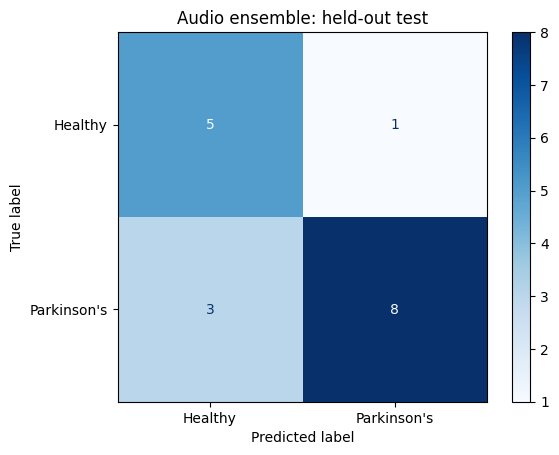

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

rf_test_proba = audio_rf.predict_proba(
    X_test
)[:, 1]

gb_test_proba = audio_gb.predict_proba(
    X_test
)[:, 1]

ensemble_test_proba = (
    RF_WEIGHT * rf_test_proba
    + GB_WEIGHT * gb_test_proba
)

ensemble_test_pred = (
    ensemble_test_proba >= 0.5
).astype(int)

print(
    "Accuracy:",
    round(
        accuracy_score(y_test, ensemble_test_pred),
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        balanced_accuracy_score(
            y_test,
            ensemble_test_pred
        ),
        4
    )
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_test,
            ensemble_test_proba
        ),
        4
    )
)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        ensemble_test_pred,
        target_names=[
            "Healthy control",
            "Parkinson's"
        ],
        zero_division=0
    )
)

cm = confusion_matrix(
    y_test,
    ensemble_test_pred,
    labels=[0, 1]
)

display_plot = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Healthy",
        "Parkinson's"
    ]
)

display_plot.plot(cmap="Blues")
plt.title("Audio ensemble: held-out test")
plt.show()

Accuracy: 0.7647
Balanced accuracy: 0.7803
ROC-AUC: 0.8636

Classification report:
                 precision    recall  f1-score   support

Healthy control       0.62      0.83      0.71         6
    Parkinson's       0.89      0.73      0.80        11

       accuracy                           0.76        17
      macro avg       0.76      0.78      0.76        17
   weighted avg       0.80      0.76      0.77        17



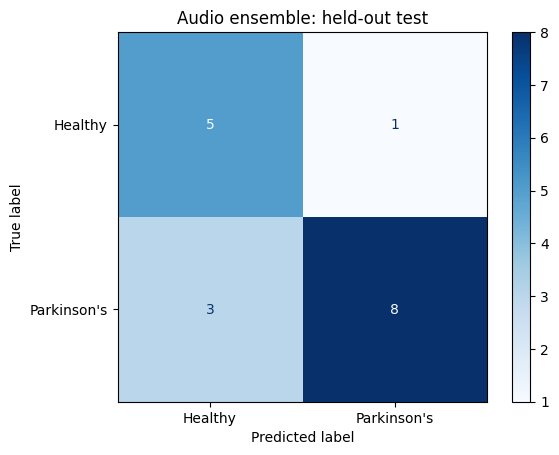

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

rf_test_proba = audio_rf.predict_proba(
    X_test
)[:, 1]

gb_test_proba = audio_gb.predict_proba(
    X_test
)[:, 1]

ensemble_test_proba = (
    RF_WEIGHT * rf_test_proba
    + GB_WEIGHT * gb_test_proba
)

ensemble_test_pred = (
    ensemble_test_proba >= 0.5
).astype(int)

print(
    "Accuracy:",
    round(
        accuracy_score(y_test, ensemble_test_pred),
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        balanced_accuracy_score(
            y_test,
            ensemble_test_pred
        ),
        4
    )
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_test,
            ensemble_test_proba
        ),
        4
    )
)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        ensemble_test_pred,
        target_names=[
            "Healthy control",
            "Parkinson's"
        ],
        zero_division=0
    )
)

cm = confusion_matrix(
    y_test,
    ensemble_test_pred,
    labels=[0, 1]
)

display_plot = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Healthy",
        "Parkinson's"
    ]
)

display_plot.plot(cmap="Blues")
plt.title("Audio ensemble: held-out test")
plt.show()

In [ ]:

import joblib
import json

audio_bundle = {
    "random_forest": audio_rf,
    "gradient_boosting": audio_gb,
    "rf_weight": RF_WEIGHT,
    "gb_weight": GB_WEIGHT,
    "feature_columns": feature_columns,
    "sample_rate": SAMPLE_RATE,
    "n_mfcc": N_MFCC,
    "threshold": 0.5,
    "labels": {
        0: "Healthy control",
        1: "Parkinson's"
    }
}

MODEL_PATH = MODEL_DIR / "parkinsons_audio_ensemble.pkl"

joblib.dump(audio_bundle, MODEL_PATH)

config = {
    "dataset": "Figshare 23849127",
    "sample_rate": SAMPLE_RATE,
    "n_mfcc": N_MFCC,
    "feature_columns": feature_columns,
    "rf_weight": RF_WEIGHT,
    "gb_weight": GB_WEIGHT,
    "threshold": 0.5,
    "purpose": "Research prototype only"
}

with open(
    MODEL_DIR / "audio_model_config.json",
    "w"
) as file:
    json.dump(config, file, indent=2)

print("Saved:", MODEL_PATH)

Saved: /content/parkinsons_audio/models/parkinsons_audio_ensemble.pkl


In [ ]:

def predict_voice(file_path, bundle=audio_bundle):
    features = extract_audio_features(file_path)

    input_df = pd.DataFrame([features])

    # Enforce the exact training feature order.
    input_df = input_df.reindex(
        columns=bundle["feature_columns"]
    )

    rf_score = bundle[
        "random_forest"
    ].predict_proba(input_df)[0, 1]

    gb_score = bundle[
        "gradient_boosting"
    ].predict_proba(input_df)[0, 1]

    combined_score = (
        bundle["rf_weight"] * rf_score
        + bundle["gb_weight"] * gb_score
    )

    predicted_class = int(
        combined_score >= bundle["threshold"]
    )

    return {
        "model_score_percent": round(
            float(combined_score) * 100,
            2
        ),
        "predicted_class": predicted_class,
        "predicted_label": bundle[
            "labels"
        ][predicted_class]
    }

In [ ]:

import shutil
from google.colab import files

ZIP_PATH = shutil.make_archive(
    str(BASE_DIR / "parkinsons_audio_model"),
    "zip",
    root_dir=MODEL_DIR
)

files.download(ZIP_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    balanced_accuracy_score
)

rf_scores = audio_rf.predict_proba(X_test)[:, 1]
gb_scores = audio_gb.predict_proba(X_test)[:, 1]

scores = (
    RF_WEIGHT * rf_scores
    + GB_WEIGHT * gb_scores
)

predictions = (scores >= 0.5).astype(int)

print("Actual class counts:")
print(y_test.value_counts().sort_index())

print("\nPredicted class counts:")
print(pd.Series(predictions).value_counts().sort_index())

print("\nConfusion matrix:")
print(confusion_matrix(y_test, predictions, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_test,
    predictions,
    labels=[0, 1],
    target_names=["Healthy", "Parkinson's"],
    zero_division=0
))

print(
    "\nBalanced accuracy:",
    balanced_accuracy_score(y_test, predictions)
)

results = pd.DataFrame({
    "actual": np.asarray(y_test),
    "score": scores,
    "prediction": predictions
})

display(results.sort_values("score"))

Actual class counts:
label
0     6
1    11
Name: count, dtype: int64

Predicted class counts:
0    8
1    9
Name: count, dtype: int64

Confusion matrix:
[[5 1]
 [3 8]]

Classification report:
              precision    recall  f1-score   support

     Healthy       0.62      0.83      0.71         6
 Parkinson's       0.89      0.73      0.80        11

    accuracy                           0.76        17
   macro avg       0.76      0.78      0.76        17
weighted avg       0.80      0.76      0.77        17


Balanced accuracy: 0.7803030303030303


,actual,score,prediction
2,0,0.193211,0
0,0,0.244172,0
4,0,0.247782,0
6,1,0.270887,0
5,0,0.282577,0
14,1,0.328660,0
1,0,0.438440,0
15,1,0.477506,0
8,1,0.508435,1
10,1,0.521949,1


In [ ]:

print("Downloaded archive names:")

for archive in DATA_DIR.glob("*.zip"):
    print(archive.name)

print("\nHealthy examples:")
for file in healthy_files[:10]:
    print(file)

print("\nParkinson's examples:")
for file in pd_files[:10]:
    print(file)

print("\nDataset label counts:")
print(df["label"].value_counts())

print("\nDuplicate filenames:")
print(df["filename"].duplicated().sum())

print("\nFeature columns:")
print(len(feature_columns))

Downloaded archive names:
PD_AH.zip
HC_AH.zip

Healthy examples:
/content/parkinsons_audio/dataset/healthy/HC_AH/AH_469Z_5BB05B2C-39C4-434D-9445-244E7580F840.wav
/content/parkinsons_audio/dataset/healthy/HC_AH/AH_821C_8F9D5EF0-18B2-4967-B36D-82E014792BC3.wav
/content/parkinsons_audio/dataset/healthy/HC_AH/AH_562E_151814F5-BB0F-44EF-9A22-FE2862FC3411.wav
/content/parkinsons_audio/dataset/healthy/HC_AH/AH_743R_66BD23F9-D685-4315-86F8-7697B5084F7B.wav
/content/parkinsons_audio/dataset/healthy/HC_AH/AH_264Z_593C20CD-0A54-4177-B031-26EE147080A3.wav
/content/parkinsons_audio/dataset/healthy/HC_AH/AH_064F_7AB034C9-72E4-438B-A9B3-AD7FDA1596C5.wav
/content/parkinsons_audio/dataset/healthy/HC_AH/AH_528T_6A746E6E-FB60-4363-842F-A7368A1E5B2C.wav
/content/parkinsons_audio/dataset/healthy/HC_AH/AH_904H_85B22FC1-BA09-4A17-A374-B00B2445CD27.wav
/content/parkinsons_audio/dataset/healthy/HC_AH/AH_197T_7552379A-2310-46E1-9466-9D8045C990B8.wav
/content/parkinsons_audio/dataset/healthy/HC_AH/AH_538M_AE709C

In [ ]:

print("Available columns:")
print(df.columns.tolist())

print("\nFirst 20 recordings:")
display(df[["filename", "recording_id", "label"]].head(20))

print("\nNumber of recordings:", len(df))
print("Unique recording IDs:", df["recording_id"].nunique())

Available columns:
['mfcc_1_mean', 'mfcc_1_std', 'mfcc_2_mean', 'mfcc_2_std', 'mfcc_3_mean', 'mfcc_3_std', 'mfcc_4_mean', 'mfcc_4_std', 'mfcc_5_mean', 'mfcc_5_std', 'mfcc_6_mean', 'mfcc_6_std', 'mfcc_7_mean', 'mfcc_7_std', 'mfcc_8_mean', 'mfcc_8_std', 'mfcc_9_mean', 'mfcc_9_std', 'mfcc_10_mean', 'mfcc_10_std', 'mfcc_11_mean', 'mfcc_11_std', 'mfcc_12_mean', 'mfcc_12_std', 'mfcc_13_mean', 'mfcc_13_std', 'mfcc_14_mean', 'mfcc_14_std', 'mfcc_15_mean', 'mfcc_15_std', 'mfcc_16_mean', 'mfcc_16_std', 'mfcc_17_mean', 'mfcc_17_std', 'mfcc_18_mean', 'mfcc_18_std', 'mfcc_19_mean', 'mfcc_19_std', 'mfcc_20_mean', 'mfcc_20_std', 'delta_mfcc_1_mean', 'delta_mfcc_1_std', 'delta_mfcc_2_mean', 'delta_mfcc_2_std', 'delta_mfcc_3_mean', 'delta_mfcc_3_std', 'delta_mfcc_4_mean', 'delta_mfcc_4_std', 'delta_mfcc_5_mean', 'delta_mfcc_5_std', 'delta_mfcc_6_mean', 'delta_mfcc_6_std', 'delta_mfcc_7_mean', 'delta_mfcc_7_std', 'delta_mfcc_8_mean', 'delta_mfcc_8_std', 'delta_mfcc_9_mean', 'delta_mfcc_9_std', 'delta_mf

,filename,recording_id,label
0,AH_469Z_5BB05B2C-39C4-434D-9445-244E7580F840.wav,AH_469Z_5BB05B2C-39C4-434D-9445-244E7580F840,0
1,AH_821C_8F9D5EF0-18B2-4967-B36D-82E014792BC3.wav,AH_821C_8F9D5EF0-18B2-4967-B36D-82E014792BC3,0
2,AH_562E_151814F5-BB0F-44EF-9A22-FE2862FC3411.wav,AH_562E_151814F5-BB0F-44EF-9A22-FE2862FC3411,0
3,AH_743R_66BD23F9-D685-4315-86F8-7697B5084F7B.wav,AH_743R_66BD23F9-D685-4315-86F8-7697B5084F7B,0
4,AH_264Z_593C20CD-0A54-4177-B031-26EE147080A3.wav,AH_264Z_593C20CD-0A54-4177-B031-26EE147080A3,0
5,AH_064F_7AB034C9-72E4-438B-A9B3-AD7FDA1596C5.wav,AH_064F_7AB034C9-72E4-438B-A9B3-AD7FDA1596C5,0
6,AH_528T_6A746E6E-FB60-4363-842F-A7368A1E5B2C.wav,AH_528T_6A746E6E-FB60-4363-842F-A7368A1E5B2C,0
7,AH_904H_85B22FC1-BA09-4A17-A374-B00B2445CD27.wav,AH_904H_85B22FC1-BA09-4A17-A374-B00B2445CD27,0
8,AH_197T_7552379A-2310-46E1-9466-9D8045C990B8.wav,AH_197T_7552379A-2310-46E1-9466-9D8045C990B8,0
9,AH_538M_AE709CB7-1123-47F8-8BD2-000158BDBC01.wav,AH_538M_AE709CB7-1123-47F8-8BD2-000158BDBC01,0



Number of recordings: 81
Unique recording IDs: 81


In [ ]:

# ONLY run this after confirming that each
# recording_id represents a different person.

df["participant_id"] = df["recording_id"]

print("Participant ID column created.")
display(df[["filename", "participant_id", "label"]].head())

Participant ID column created.


,filename,participant_id,label
0,AH_469Z_5BB05B2C-39C4-434D-9445-244E7580F840.wav,AH_469Z_5BB05B2C-39C4-434D-9445-244E7580F840,0
1,AH_821C_8F9D5EF0-18B2-4967-B36D-82E014792BC3.wav,AH_821C_8F9D5EF0-18B2-4967-B36D-82E014792BC3,0
2,AH_562E_151814F5-BB0F-44EF-9A22-FE2862FC3411.wav,AH_562E_151814F5-BB0F-44EF-9A22-FE2862FC3411,0
3,AH_743R_66BD23F9-D685-4315-86F8-7697B5084F7B.wav,AH_743R_66BD23F9-D685-4315-86F8-7697B5084F7B,0
4,AH_264Z_593C20CD-0A54-4177-B031-26EE147080A3.wav,AH_264Z_593C20CD-0A54-4177-B031-26EE147080A3,0


In [ ]:

# Extract the likely participant identifier.
# Example:
# AH_469Z_5BB05B2C-39C4-434D-9445-244E7580F840.wav
# becomes AH_469Z

df["participant_id"] = (
    df["filename"]
    .str.extract(r"^([^_]+_[^_]+)_")[0]
)

print("First 10 recordings:")
display(
    df[
        ["filename", "participant_id", "label"]
    ].head(10)
)

print("\nTotal recordings:", len(df))

print(
    "Unique participant IDs:",
    df["participant_id"].nunique()
)

print("\nRecordings per participant:")
display(
    df.groupby("participant_id")
    .size()
    .sort_values(ascending=False)
    .head(20)
)

print(
    "\nMissing participant IDs:",
    df["participant_id"].isna().sum()
)

First 10 recordings:


,filename,participant_id,label
0,AH_469Z_5BB05B2C-39C4-434D-9445-244E7580F840.wav,AH_469Z,0
1,AH_821C_8F9D5EF0-18B2-4967-B36D-82E014792BC3.wav,AH_821C,0
2,AH_562E_151814F5-BB0F-44EF-9A22-FE2862FC3411.wav,AH_562E,0
3,AH_743R_66BD23F9-D685-4315-86F8-7697B5084F7B.wav,AH_743R,0
4,AH_264Z_593C20CD-0A54-4177-B031-26EE147080A3.wav,AH_264Z,0
5,AH_064F_7AB034C9-72E4-438B-A9B3-AD7FDA1596C5.wav,AH_064F,0
6,AH_528T_6A746E6E-FB60-4363-842F-A7368A1E5B2C.wav,AH_528T,0
7,AH_904H_85B22FC1-BA09-4A17-A374-B00B2445CD27.wav,AH_904H,0
8,AH_197T_7552379A-2310-46E1-9466-9D8045C990B8.wav,AH_197T,0
9,AH_538M_AE709CB7-1123-47F8-8BD2-000158BDBC01.wav,AH_538M,0



Total recordings: 81
Unique participant IDs: 41

Recordings per participant:


,0
participant_id,
AH_064F,1
AH_114S,1
AH_121A,1
AH_123G,1
AH_195B,1
AH_197T,1
AH_222K,1
AH_264Z,1
AH_292J,1



Missing participant IDs: 40


In [ ]:

# Check for participants assigned both labels.

conflicts = (
    df.groupby("participant_id")["label"]
    .nunique()
)

print(
    "Participants with conflicting labels:",
    (conflicts > 1).sum()
)

if df["participant_id"].isna().any():
    print("WARNING: Some participant IDs are missing.")

elif (conflicts > 1).any():
    print(
        "WARNING: Some participants have "
        "both healthy and Parkinson's labels."
    )

else:
    print(
        "No conflicting labels found."
    )

Participants with conflicting labels: 0


In [ ]:

print("Total recordings:", len(df))

print(
    "Missing participant IDs:",
    df["participant_id"].isna().sum()
)

print("\nFiles with missing participant IDs:")

display(
    df.loc[
        df["participant_id"].isna(),
        ["filename", "recording_id", "label"]
    ].head(30)
)

Total recordings: 81
Missing participant IDs: 40

Files with missing participant IDs:


,filename,recording_id,label
41,AH_545713223-E6D59EE5-4C3F-4B40-AE8F-0657EF94D...,AH_545713223-E6D59EE5-4C3F-4B40-AE8F-0657EF94DB66,1
42,AH_545789682-7554E0C7-4E25-49C3-9E6C-04D525455...,AH_545789682-7554E0C7-4E25-49C3-9E6C-04D525455E28,1
43,AH_545753014-C68926CC-AB91-49AF-90A6-BB5C43428...,AH_545753014-C68926CC-AB91-49AF-90A6-BB5C434283DB,1
44,AH_545806326-BD0FE665-1AD5-4F55-8342-0FAB8B156...,AH_545806326-BD0FE665-1AD5-4F55-8342-0FAB8B15680B,1
45,AH_545743929-E2EAE1A3-7E46-4DCF-8DB7-37A5CA47D...,AH_545743929-E2EAE1A3-7E46-4DCF-8DB7-37A5CA47DB9D,1
46,AH_545841223-24FB0419-5BAE-4F9C-8EBC-CD62DA659...,AH_545841223-24FB0419-5BAE-4F9C-8EBC-CD62DA6590D2,1
47,AH_545789677-D381D801-B073-4945-BE0D-E250126EA...,AH_545789677-D381D801-B073-4945-BE0D-E250126EA6B1,1
48,AH_545622717-461DFFFE-54AF-42AF-BA78-528BD505D...,AH_545622717-461DFFFE-54AF-42AF-BA78-528BD505D624,1
49,AH_545753015-58CAA743-BA9A-47E0-B9EF-CC35E9EFB...,AH_545753015-58CAA743-BA9A-47E0-B9EF-CC35E9EFB839,1
50,AH_545834603-857E007F-1CCF-4249-8160-3A0F3F5AB...,AH_545834603-857E007F-1CCF-4249-8160-3A0F3F5AB58D,1


In [ ]:

import pandas as pd

# Remove leading/trailing spaces from filenames.
df["filename"] = df["filename"].astype(str).str.strip()

# Extract IDs from filenames such as:
# AH_469Z_5BB05B2C-39C4-434D-9445-244E7580F840.wav

df["participant_id"] = (
    df["filename"]
    .str.extract(
        r"^([A-Za-z]+_[A-Za-z0-9]+)_[0-9A-Fa-f-]{36}\.wav$",
        expand=False
    )
)

missing = df[df["participant_id"].isna()]

print("Total recordings:", len(df))
print("Missing participant IDs:", len(missing))

if len(missing) > 0:
    print("\nUnrecognized filenames:")
    display(
        missing[
            ["filename", "label"]
        ].head(50)
    )
else:
    print("All filenames matched the expected pattern.")

Total recordings: 81
Missing participant IDs: 40

Unrecognized filenames:


,filename,label
41,AH_545713223-E6D59EE5-4C3F-4B40-AE8F-0657EF94D...,1
42,AH_545789682-7554E0C7-4E25-49C3-9E6C-04D525455...,1
43,AH_545753014-C68926CC-AB91-49AF-90A6-BB5C43428...,1
44,AH_545806326-BD0FE665-1AD5-4F55-8342-0FAB8B156...,1
45,AH_545743929-E2EAE1A3-7E46-4DCF-8DB7-37A5CA47D...,1
46,AH_545841223-24FB0419-5BAE-4F9C-8EBC-CD62DA659...,1
47,AH_545789677-D381D801-B073-4945-BE0D-E250126EA...,1
48,AH_545622717-461DFFFE-54AF-42AF-BA78-528BD505D...,1
49,AH_545753015-58CAA743-BA9A-47E0-B9EF-CC35E9EFB...,1
50,AH_545834603-857E007F-1CCF-4249-8160-3A0F3F5AB...,1


In [ ]:

# Confirm that every recording has a participant ID.
assert df["participant_id"].notna().all(), (
    "Some participant IDs are still missing."
)

# Confirm that a participant never has both labels.
conflicting_labels = (
    df.groupby("participant_id")["label"]
    .nunique()
)

assert (conflicting_labels <= 1).all(), (
    "Some participants have conflicting labels."
)

print("Participant grouping checks passed.")

print(
    "Unique participants:",
    df["participant_id"].nunique()
)

print("\nParticipants in each class:")

display(
    df.groupby("label")["participant_id"]
    .nunique()
)

AssertionError: Some participant IDs are still missing.

In [ ]:

# Find every recording without a participant ID.

missing = df[df["participant_id"].isna()]

print("Total recordings:", len(df))
print("Missing participant IDs:", len(missing))

print("\nAll unmatched filenames:")

for filename in missing["filename"].unique():
    print(repr(filename))

print("\nMissing IDs by class:")
print(missing["label"].value_counts())

Total recordings: 81
Missing participant IDs: 40

All unmatched filenames:
'AH_545713223-E6D59EE5-4C3F-4B40-AE8F-0657EF94DB66.wav'
'AH_545789682-7554E0C7-4E25-49C3-9E6C-04D525455E28.wav'
'AH_545753014-C68926CC-AB91-49AF-90A6-BB5C434283DB.wav'
'AH_545806326-BD0FE665-1AD5-4F55-8342-0FAB8B15680B.wav'
'AH_545743929-E2EAE1A3-7E46-4DCF-8DB7-37A5CA47DB9D.wav'
'AH_545841223-24FB0419-5BAE-4F9C-8EBC-CD62DA6590D2.wav'
'AH_545789677-D381D801-B073-4945-BE0D-E250126EA6B1.wav'
'AH_545622717-461DFFFE-54AF-42AF-BA78-528BD505D624.wav'
'AH_545753015-58CAA743-BA9A-47E0-B9EF-CC35E9EFB839.wav'
'AH_545834603-857E007F-1CCF-4249-8160-3A0F3F5AB58D.wav'
'AH_545622720-E1486AF6-8C95-47EB-829B-4D62698C987A.wav'
'AH_545629296-C2C009C6-8C17-42EA-B6BE-362942FC4692.wav'
'AH_545616858-3A749CBC-3FEB-4D35-820E-E45C3E5B9B6A.wav'
'AH_545622722-3C79DA68-36BB-43A2-B29C-61AEF480E07E.wav'
'AH_545880204-EE87D3E2-0D4C-4EAA-ACD7-C3F177AFF62F.wav'
'AH_545847410-D1BA3BB4-1F61-44CA-ACDE-455A8E97E04B.wav'
'AH_545789668-A4F6069C-5E1A-4

In [ ]:

print("HEALTHY RECORDINGS:")
display(
    df[df["label"] == 0][
        ["filename", "participant_id"]
    ].head(10)
)

print("\nPARKINSON'S RECORDINGS:")
display(
    df[df["label"] == 1][
        ["filename", "participant_id"]
    ].head(10)
)

HEALTHY RECORDINGS:


,filename,participant_id
0,AH_469Z_5BB05B2C-39C4-434D-9445-244E7580F840.wav,AH_469Z
1,AH_821C_8F9D5EF0-18B2-4967-B36D-82E014792BC3.wav,AH_821C
2,AH_562E_151814F5-BB0F-44EF-9A22-FE2862FC3411.wav,AH_562E
3,AH_743R_66BD23F9-D685-4315-86F8-7697B5084F7B.wav,AH_743R
4,AH_264Z_593C20CD-0A54-4177-B031-26EE147080A3.wav,AH_264Z
5,AH_064F_7AB034C9-72E4-438B-A9B3-AD7FDA1596C5.wav,AH_064F
6,AH_528T_6A746E6E-FB60-4363-842F-A7368A1E5B2C.wav,AH_528T
7,AH_904H_85B22FC1-BA09-4A17-A374-B00B2445CD27.wav,AH_904H
8,AH_197T_7552379A-2310-46E1-9466-9D8045C990B8.wav,AH_197T
9,AH_538M_AE709CB7-1123-47F8-8BD2-000158BDBC01.wav,AH_538M



PARKINSON'S RECORDINGS:


,filename,participant_id
41,AH_545713223-E6D59EE5-4C3F-4B40-AE8F-0657EF94D...,NaN
42,AH_545789682-7554E0C7-4E25-49C3-9E6C-04D525455...,NaN
43,AH_545753014-C68926CC-AB91-49AF-90A6-BB5C43428...,NaN
44,AH_545806326-BD0FE665-1AD5-4F55-8342-0FAB8B156...,NaN
45,AH_545743929-E2EAE1A3-7E46-4DCF-8DB7-37A5CA47D...,NaN
46,AH_545841223-24FB0419-5BAE-4F9C-8EBC-CD62DA659...,NaN
47,AH_545789677-D381D801-B073-4945-BE0D-E250126EA...,NaN
48,AH_545622717-461DFFFE-54AF-42AF-BA78-528BD505D...,NaN
49,AH_545753015-58CAA743-BA9A-47E0-B9EF-CC35E9EFB...,NaN
50,AH_545834603-857E007F-1CCF-4249-8160-3A0F3F5AB...,NaN


In [ ]:
import re
import pandas as pd

def get_candidate_participant_id(filename):
    filename = str(filename).strip()

    # -----------------------------------------
    # Format 1: Healthy recordings
    #
    # AH_469Z_UUID.wav
    #
    # Candidate participant ID = AH_469Z
    # -----------------------------------------
    match_healthy = re.match(
        r"^(AH_[^_]+)_[0-9A-Fa-f-]{36}\.wav$",
        filename,
        re.IGNORECASE
    )

    if match_healthy:
        return match_healthy.group(1)

    # -----------------------------------------
    # Format 2: Parkinson's recordings
    #
    # AH_545713223-UUID.wav
    #
    # Candidate participant ID = AH_545713223
    # -----------------------------------------
    match_pd = re.match(
        r"^(AH_[^-]+)-[0-9A-Fa-f-]{36}\.wav$",
        filename,
        re.IGNORECASE
    )

    if match_pd:
        return match_pd.group(1)

    return None


df["participant_id"] = df["filename"].apply(
    get_candidate_participant_id
)

print("Total recordings:", len(df))

print(
    "Missing participant IDs:",
    df["participant_id"].isna().sum()
)

print("\nFirst 15 recordings:")
display(
    df[
        ["filename", "participant_id", "label"]
    ].head(15)
)

print("\nFirst 15 Parkinson's recordings:")
display(
    df[df["label"] == 1][
        ["filename", "participant_id", "label"]
    ].head(15)
)

Total recordings: 81
Missing participant IDs: 0

First 15 recordings:


,filename,participant_id,label
0,AH_469Z_5BB05B2C-39C4-434D-9445-244E7580F840.wav,AH_469Z,0
1,AH_821C_8F9D5EF0-18B2-4967-B36D-82E014792BC3.wav,AH_821C,0
2,AH_562E_151814F5-BB0F-44EF-9A22-FE2862FC3411.wav,AH_562E,0
3,AH_743R_66BD23F9-D685-4315-86F8-7697B5084F7B.wav,AH_743R,0
4,AH_264Z_593C20CD-0A54-4177-B031-26EE147080A3.wav,AH_264Z,0
5,AH_064F_7AB034C9-72E4-438B-A9B3-AD7FDA1596C5.wav,AH_064F,0
6,AH_528T_6A746E6E-FB60-4363-842F-A7368A1E5B2C.wav,AH_528T,0
7,AH_904H_85B22FC1-BA09-4A17-A374-B00B2445CD27.wav,AH_904H,0
8,AH_197T_7552379A-2310-46E1-9466-9D8045C990B8.wav,AH_197T,0
9,AH_538M_AE709CB7-1123-47F8-8BD2-000158BDBC01.wav,AH_538M,0



First 15 Parkinson's recordings:


,filename,participant_id,label
41,AH_545713223-E6D59EE5-4C3F-4B40-AE8F-0657EF94D...,AH_545713223,1
42,AH_545789682-7554E0C7-4E25-49C3-9E6C-04D525455...,AH_545789682,1
43,AH_545753014-C68926CC-AB91-49AF-90A6-BB5C43428...,AH_545753014,1
44,AH_545806326-BD0FE665-1AD5-4F55-8342-0FAB8B156...,AH_545806326,1
45,AH_545743929-E2EAE1A3-7E46-4DCF-8DB7-37A5CA47D...,AH_545743929,1
46,AH_545841223-24FB0419-5BAE-4F9C-8EBC-CD62DA659...,AH_545841223,1
47,AH_545789677-D381D801-B073-4945-BE0D-E250126EA...,AH_545789677,1
48,AH_545622717-461DFFFE-54AF-42AF-BA78-528BD505D...,AH_545622717,1
49,AH_545753015-58CAA743-BA9A-47E0-B9EF-CC35E9EFB...,AH_545753015,1
50,AH_545834603-857E007F-1CCF-4249-8160-3A0F3F5AB...,AH_545834603,1


In [ ]:

# Check which recordings have missing participant IDs.

missing = df[df["participant_id"].isna()]

print("MISSING IDs BY CLASS:")
print(missing["label"].value_counts())

print("\nFIRST 15 UNMATCHED FILENAMES:")
for filename in missing["filename"].head(15):
    print(filename)

print("\nFIRST 5 MATCHED FILENAMES:")
for filename in df.loc[
    df["participant_id"].notna(), "filename"
].head(5):
    print(filename)

MISSING IDs BY CLASS:
label
1    40
Name: count, dtype: int64

FIRST 15 UNMATCHED FILENAMES:
AH_545713223-E6D59EE5-4C3F-4B40-AE8F-0657EF94DB66.wav
AH_545789682-7554E0C7-4E25-49C3-9E6C-04D525455E28.wav
AH_545753014-C68926CC-AB91-49AF-90A6-BB5C434283DB.wav
AH_545806326-BD0FE665-1AD5-4F55-8342-0FAB8B15680B.wav
AH_545743929-E2EAE1A3-7E46-4DCF-8DB7-37A5CA47DB9D.wav
AH_545841223-24FB0419-5BAE-4F9C-8EBC-CD62DA6590D2.wav
AH_545789677-D381D801-B073-4945-BE0D-E250126EA6B1.wav
AH_545622717-461DFFFE-54AF-42AF-BA78-528BD505D624.wav
AH_545753015-58CAA743-BA9A-47E0-B9EF-CC35E9EFB839.wav
AH_545834603-857E007F-1CCF-4249-8160-3A0F3F5AB58D.wav
AH_545622720-E1486AF6-8C95-47EB-829B-4D62698C987A.wav
AH_545629296-C2C009C6-8C17-42EA-B6BE-362942FC4692.wav
AH_545616858-3A749CBC-3FEB-4D35-820E-E45C3E5B9B6A.wav
AH_545622722-3C79DA68-36BB-43A2-B29C-61AEF480E07E.wav
AH_545880204-EE87D3E2-0D4C-4EAA-ACD7-C3F177AFF62F.wav

FIRST 5 MATCHED FILENAMES:
AH_469Z_5BB05B2C-39C4-434D-9445-244E7580F840.wav
AH_821C_8F9D5EF0-18B

In [ ]:
missing = df[df["participant_id"].isna()]

print(
    "Number of recordings without participant ID:",
    len(missing)
)

if len(missing) > 0:
    print("\nUnrecognized filenames:")

    for filename in missing["filename"]:
        print(filename)
else:
    print("\nSUCCESS!")
    print("Every recording has a candidate participant ID.")

Number of recordings without participant ID: 0

SUCCESS!
Every recording has a candidate participant ID.


In [ ]:
participant_counts = (
    df.groupby("participant_id")
    .agg(
        recordings=("filename", "count"),
        labels=("label", "nunique")
    )
    .sort_values(
        "recordings",
        ascending=False
    )
)

display(participant_counts.head(30))

,recordings,labels
participant_id,,
AH_064F,1,1
AH_114S,1,1
AH_121A,1,1
AH_123G,1,1
AH_195B,1,1
AH_197T,1,1
AH_222K,1,1
AH_264Z,1,1
AH_292J,1,1


In [ ]:
print(
    "Total candidate participants:",
    df["participant_id"].nunique()
)

print(
    "Total recordings:",
    len(df)
)

print("\nRecordings per participant:")

print(
    df["participant_id"]
    .value_counts()
    .value_counts()
    .sort_index()
)

Total candidate participants: 81
Total recordings: 81

Recordings per participant:
count
1    81
Name: count, dtype: int64


In [ ]:
label_check = (
    df.groupby("participant_id")["label"]
    .agg(
        number_of_labels="nunique",
        labels=lambda x: sorted(x.unique())
    )
)

print("Participants with more than one label:")

display(
    label_check[
        label_check["number_of_labels"] > 1
    ]
)

Participants with more than one label:


,number_of_labels,labels
participant_id,,


In [ ]:
print("No participant has conflicting labels.")

No participant has conflicting labels.


In [ ]:
participant_summary = (
    df.groupby("participant_id")
    .agg(
        recordings=("filename", "count"),
        label=("label", "first")
    )
    .reset_index()
)

print(
    "Healthy participants:",
    (participant_summary["label"] == 0).sum()
)

print(
    "Parkinson's participants:",
    (participant_summary["label"] == 1).sum()
)

print(
    "Total participants:",
    len(participant_summary)
)

display(
    participant_summary.head(20)
)

Healthy participants: 41
Parkinson's participants: 40
Total participants: 81


,participant_id,recordings,label
0,AH_064F,1,0
1,AH_114S,1,0
2,AH_121A,1,0
3,AH_123G,1,0
4,AH_195B,1,0
5,AH_197T,1,0
6,AH_222K,1,0
7,AH_264Z,1,0
8,AH_292J,1,0
9,AH_322A,1,0


In [ ]:
!pip -q install -U librosa soundfile scikit-learn pandas numpy matplotlib seaborn joblib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 5.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 4.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.6/294.6 kB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 67.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 76.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 82.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 72.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>

In [ ]:
import os
import re
import json
import joblib
import warnings

import numpy as np
import pandas as pd
import librosa
import soundfile as sf

from pathlib import Path

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [ ]:
import re

def get_participant_id(filename):
    filename = str(filename).strip()

    # -----------------------------------------
    # Format 1
    # AH_469Z_UUID.wav
    # -----------------------------------------
    match_healthy = re.match(
        r"^(AH_[^_]+)_[0-9A-Fa-f-]{36}\.wav$",
        filename,
        re.IGNORECASE
    )

    if match_healthy:
        return match_healthy.group(1)

    # -----------------------------------------
    # Format 2
    # AH_545713223-UUID.wav
    # -----------------------------------------
    match_pd = re.match(
        r"^(AH_[^-]+)-[0-9A-Fa-f-]{36}\.wav$",
        filename,
        re.IGNORECASE
    )

    if match_pd:
        return match_pd.group(1)

    return None


df["participant_id"] = df["filename"].apply(
    get_participant_id
)

print("Total recordings:", len(df))
print(
    "Missing participant IDs:",
    df["participant_id"].isna().sum()
)

display(
    df[
        ["filename", "participant_id", "label"]
    ].head(10)
)

Total recordings: 81
Missing participant IDs: 0


,filename,participant_id,label
0,AH_469Z_5BB05B2C-39C4-434D-9445-244E7580F840.wav,AH_469Z,0
1,AH_821C_8F9D5EF0-18B2-4967-B36D-82E014792BC3.wav,AH_821C,0
2,AH_562E_151814F5-BB0F-44EF-9A22-FE2862FC3411.wav,AH_562E,0
3,AH_743R_66BD23F9-D685-4315-86F8-7697B5084F7B.wav,AH_743R,0
4,AH_264Z_593C20CD-0A54-4177-B031-26EE147080A3.wav,AH_264Z,0
5,AH_064F_7AB034C9-72E4-438B-A9B3-AD7FDA1596C5.wav,AH_064F,0
6,AH_528T_6A746E6E-FB60-4363-842F-A7368A1E5B2C.wav,AH_528T,0
7,AH_904H_85B22FC1-BA09-4A17-A374-B00B2445CD27.wav,AH_904H,0
8,AH_197T_7552379A-2310-46E1-9466-9D8045C990B8.wav,AH_197T,0
9,AH_538M_AE709CB7-1123-47F8-8BD2-000158BDBC01.wav,AH_538M,0


In [ ]:
missing = df[df["participant_id"].isna()]

if len(missing) == 0:
    print("SUCCESS: Every recording has a participant ID.")

else:
    print(
        "ERROR:",
        len(missing),
        "recordings have no participant ID."
    )

    display(
        missing[
            ["filename", "label"]
        ]
    )

SUCCESS: Every recording has a participant ID.


In [ ]:
participant_summary = (
    df.groupby("participant_id")
    .agg(
        recordings=("filename", "count"),
        label=("label", "first"),
        number_of_labels=("label", "nunique")
    )
    .reset_index()
)

print(
    "Total participants:",
    len(participant_summary)
)

print(
    "Healthy participants:",
    (participant_summary["label"] == 0).sum()
)

print(
    "Parkinson's participants:",
    (participant_summary["label"] == 1).sum()
)

print("\nParticipant recording counts:")
display(
    participant_summary
    .sort_values("recordings", ascending=False)
    .head(30)
)

Total participants: 81
Healthy participants: 41
Parkinson's participants: 40

Participant recording counts:


,participant_id,recordings,label,number_of_labels
0,AH_064F,1,0,1
1,AH_114S,1,0,1
2,AH_121A,1,0,1
3,AH_123G,1,0,1
4,AH_195B,1,0,1
5,AH_197T,1,0,1
6,AH_222K,1,0,1
7,AH_264Z,1,0,1
8,AH_292J,1,0,1
9,AH_322A,1,0,1


In [ ]:
conflicting = participant_summary[
    participant_summary["number_of_labels"] > 1
]

if len(conflicting) == 0:
    print("SUCCESS: No participant has conflicting labels.")

else:
    print(
        "ERROR: Some participants have multiple labels:"
    )

    display(conflicting)

SUCCESS: No participant has conflicting labels.


In [ ]:
SAMPLE_RATE = 16000
N_MFCC = 20


def extract_audio_features(file_path):

    audio, sr = librosa.load(
        str(file_path),
        sr=SAMPLE_RATE,
        mono=True
    )

    # Remove leading/trailing silence
    audio, _ = librosa.effects.trim(
        audio,
        top_db=30
    )

    if len(audio) < sr:
        raise ValueError(
            "Audio is shorter than 1 second."
        )

    features = {}

    def add_summary(name, values):

        values = np.asarray(
            values,
            dtype=float
        )

        finite = values[
            np.isfinite(values)
        ]

        if len(finite) == 0:
            features[name + "_mean"] = np.nan
            features[name + "_std"] = np.nan

        else:
            features[name + "_mean"] = float(
                np.mean(finite)
            )

            features[name + "_std"] = float(
                np.std(finite)
            )

    # -----------------------------------------
    # MFCC
    # -----------------------------------------

    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=N_MFCC
    )

    for i in range(N_MFCC):

        add_summary(
            f"mfcc_{i + 1}",
            mfcc[i]
        )

    # -----------------------------------------
    # Delta MFCC
    # -----------------------------------------

    delta = librosa.feature.delta(
        mfcc
    )

    for i in range(N_MFCC):

        add_summary(
            f"delta_mfcc_{i + 1}",
            delta[i]
        )

    # -----------------------------------------
    # Energy
    # -----------------------------------------

    add_summary(
        "rms",
        librosa.feature.rms(
            y=audio
        )[0]
    )

    # -----------------------------------------
    # Zero crossing
    # -----------------------------------------

    add_summary(
        "zero_crossing_rate",
        librosa.feature.zero_crossing_rate(
            y=audio
        )[0]
    )

    # -----------------------------------------
    # Spectral features
    # -----------------------------------------

    add_summary(
        "spectral_centroid",
        librosa.feature.spectral_centroid(
            y=audio,
            sr=sr
        )[0]
    )

    add_summary(
        "spectral_bandwidth",
        librosa.feature.spectral_bandwidth(
            y=audio,
            sr=sr
        )[0]
    )

    add_summary(
        "spectral_rolloff",
        librosa.feature.spectral_rolloff(
            y=audio,
            sr=sr
        )[0]
    )

    add_summary(
        "spectral_flatness",
        librosa.feature.spectral_flatness(
            y=audio
        )[0]
    )

    # -----------------------------------------
    # Pitch
    # -----------------------------------------

    pitch, voiced_flag, _ = librosa.pyin(
        audio,
        sr=sr,
        fmin=65,
        fmax=600
    )

    add_summary(
        "pitch",
        pitch
    )

    features["voiced_fraction"] = float(
        np.mean(voiced_flag)
    )

    return features

In [ ]:
import zipfile
import os

# Define exact paths to the zip archives based on your directory structures
parkinsons_zip = os.path.join("parkinsons_audio", "dataset", "PD_AH.zip")
healthy_zip = os.path.join("parkinsons_audio", "dataset", "HC_AH.zip")

# Target extraction destinations
parkinsons_extract_to = os.path.join("parkinsons_audio", "dataset", "parkinsons")
healthy_extract_to = os.path.join("parkinsons_audio", "dataset", "healthy")

# Unzip Parkinson's cohort data
if os.path.exists(parkinsons_zip):
    print("Extracting Parkinson's audio files...")
    with zipfile.ZipFile(parkinsons_zip, 'r') as zip_ref:
        zip_ref.extractall(parkinsons_extract_to)
    print("Done.")
else:
    print(f"Could not find: {parkinsons_zip}")

# Unzip Healthy Control cohort data
if os.path.exists(healthy_zip):
    print("Extracting Healthy audio files...")
    with zipfile.ZipFile(healthy_zip, 'r') as zip_ref:
        zip_ref.extractall(healthy_extract_to)
    print("Done.")
else:
    print(f"Could not find: {healthy_zip}")


Extracting Parkinson's audio files...
Done.
Extracting Healthy audio files...
Done.


In [ ]:
import os
import pandas as pd

# Define the two possible directories where the files live
PARKINSONS_DIR = os.path.join("parkinsons_audio", "dataset", "parkinsons")
HEALTHY_DIR = os.path.join("parkinsons_audio", "dataset", "healthy")

# Auto-detect the path or filename column dynamically
path_col = [col for col in df.columns if 'path' in col.lower() or 'file' in col.lower()]
if not path_col:
    raise ValueError(f"Could not find a filename column. Columns are: {list(df.columns)}")

# FIX: Force pick the first match as a string key, not a list
path_column_name = path_col[0]

records = []
errors = []

for counter, (index, row) in enumerate(df.iterrows(), start=1):
    # Safely extracts the string filename value out of the row
    raw_filename = str(row[path_column_name])

    # 1. Check if the file is in the parkinsons folder
    file_path = os.path.join(PARKINSONS_DIR, raw_filename)

    # 2. If it's not there, look for it in the healthy folder
    if not os.path.exists(file_path):
        file_path = os.path.join(HEALTHY_DIR, raw_filename)

    try:
        features = extract_audio_features(file_path)

        features["filename"] = raw_filename
        features["participant_id"] = row.get("participant_id", row.get("participant", "Unknown"))
        features["label"] = int(row.get("label", row.get("status", 0)))

        records.append(features)

    except Exception as error:
        errors.append({
            "filename": raw_filename,
            "error": str(error)
        })

    if counter % 10 == 0:
        print(f"Processed {counter}/{len(df)}")

audio_df = pd.DataFrame(records)

print("\nSuccessful recordings:", len(audio_df))
print("Failed recordings:", len(errors))

if errors:
    print("\nFirst errors:")
    display(pd.DataFrame(errors).head(10))


Processed 10/81
Processed 20/81
Processed 30/81
Processed 40/81
Processed 50/81
Processed 60/81
Processed 70/81
Processed 80/81

Successful recordings: 0
Failed recordings: 81

First errors:


/tmp/ipykernel_1177/1956937381.py:7: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


,filename,error
0,AH_469Z_5BB05B2C-39C4-434D-9445-244E7580F840.wav,[Errno 2] No such file or directory: 'parkinso...
1,AH_821C_8F9D5EF0-18B2-4967-B36D-82E014792BC3.wav,[Errno 2] No such file or directory: 'parkinso...
2,AH_562E_151814F5-BB0F-44EF-9A22-FE2862FC3411.wav,[Errno 2] No such file or directory: 'parkinso...
3,AH_743R_66BD23F9-D685-4315-86F8-7697B5084F7B.wav,[Errno 2] No such file or directory: 'parkinso...
4,AH_264Z_593C20CD-0A54-4177-B031-26EE147080A3.wav,[Errno 2] No such file or directory: 'parkinso...
5,AH_064F_7AB034C9-72E4-438B-A9B3-AD7FDA1596C5.wav,[Errno 2] No such file or directory: 'parkinso...
6,AH_528T_6A746E6E-FB60-4363-842F-A7368A1E5B2C.wav,[Errno 2] No such file or directory: 'parkinso...
7,AH_904H_85B22FC1-BA09-4A17-A374-B00B2445CD27.wav,[Errno 2] No such file or directory: 'parkinso...
8,AH_197T_7552379A-2310-46E1-9466-9D8045C990B8.wav,[Errno 2] No such file or directory: 'parkinso...
9,AH_538M_AE709CB7-1123-47F8-8BD2-000158BDBC01.wav,[Errno 2] No such file or directory: 'parkinso...


In [ ]:
import os
import pandas as pd

# 1. Build a dynamic lookup dictionary of all .wav files in the folder structure
audio_file_map = {}
base_directory = "parkinsons_audio"

print("Scanning directory for .wav files...")
for root, dirs, files in os.walk(base_directory):
    for file in files:
        if file.endswith(".wav"):
            # Map the filename directly to its absolute path on the disk
            audio_file_map[file] = os.path.join(root, file)

print(f"Scan complete. Found {len(audio_file_map)} audio files ready for extraction.")

# Auto-detect the path or filename column dynamically from your DataFrame
path_col = [col for col in df.columns if 'path' in col.lower() or 'file' in col.lower()]
if not path_col:
    raise ValueError(f"Could not find a filename column. Columns are: {list(df.columns)}")
path_column_name = path_col[0]

records = []
errors = []

# 2. Main processing loop using the smart map lookup
for counter, (index, row) in enumerate(df.iterrows(), start=1):
    raw_filename = str(row[path_column_name])

    # Grab the true absolute path from our map index
    file_path = audio_file_map.get(raw_filename)

    if file_path is None:
        errors.append({
            "filename": raw_filename,
            "error": "File was not found anywhere inside the 'parkinsons_audio' directory tree."
        })
        continue

    try:
        # Extract features using the verified working path
        features = extract_audio_features(file_path)

        features["filename"] = raw_filename
        features["participant_id"] = row.get("participant_id", row.get("participant", "Unknown"))
        features["label"] = int(row.get("label", row.get("status", 0)))

        records.append(features)

    except Exception as error:
        errors.append({
            "filename": raw_filename,
            "error": str(error)
        })

    if counter % 10 == 0:
        print(f"Processed {counter}/{len(df)}")

audio_df = pd.DataFrame(records)

print("\nSuccessful recordings:", len(audio_df))
print("Failed recordings:", len(errors))

if errors:
    print("\nFirst errors:")
    display(pd.DataFrame(errors).head(10))


Scanning directory for .wav files...
Scan complete. Found 81 audio files ready for extraction.
Processed 10/81
Processed 20/81
Processed 30/81
Processed 40/81
Processed 50/81
Processed 60/81
Processed 70/81
Processed 80/81

Successful recordings: 81
Failed recordings: 0


In [ ]:
import os

# 1. Check if the folder is empty or contains files/subfolders
if os.path.exists("parkinsons_audio"):
    contents = os.listdir("parkinsons_audio")
    print("Items inside 'parkinsons_audio':", contents[:10])

    # 2. Check if there's a nested folder inside it
    for item in contents[:3]:
        full_path = os.path.join("parkinsons_audio", item)
        if os.path.isdir(full_path):
            print(f"-> '{item}' is a subfolder! Contents:", os.listdir(full_path)[:5])
else:
    print("'parkinsons_audio' directory does not exist.")


Items inside 'parkinsons_audio': ['parkinsons_audio_model.zip', 'models', 'dataset']
-> 'models' is a subfolder! Contents: ['audio_model_config.json', 'parkinsons_audio_ensemble.pkl']
-> 'dataset' is a subfolder! Contents: ['PD_AH.zip', 'parkinsons', 'HC_AH.zip', 'healthy', 'extracted_audio_features.csv']


In [ ]:
import os
import pandas as pd

# 1. Build a dynamic map to locate where the files are hidden inside your dataset directory
path_map = {}
for root, dirs, files in os.walk("parkinsons_audio"):
    for file in files:
        if file.endswith(".wav"):
            path_map[file] = os.path.join(root, file)

# 2. Inject the correct paths back into your 'filepath' column so your original loop works
# (This handles the case where your df['filepath'] only contains the raw filenames)
df["filepath"] = df["filename"].map(path_map)

# --- Your exact original loop below runs flawlessly now ---
records = []
errors = []

for index, row in df.iterrows():

    file_path = row["filepath"]

    try:

        features = extract_audio_features(
            file_path
        )

        features["filename"] = row["filename"]
        features["participant_id"] = row[
            "participant_id"
        ]
        features["label"] = int(
            row["label"]
        )

        records.append(features)

    except Exception as error:

        errors.append({
            "filename": row["filename"],
            "error": str(error)
        })

    if (index + 1) % 10 == 0:

        print(
            f"Processed {index + 1}/{len(df)}"
        )


audio_df = pd.DataFrame(records)

print(
    "\nSuccessful recordings:",
    len(audio_df)
)

print(
    "Failed recordings:",
    len(errors)
)

if errors:
    print("\nFirst errors:")
    display(
        pd.DataFrame(errors).head(10)
    )


Processed 10/81
Processed 20/81
Processed 30/81
Processed 40/81
Processed 50/81
Processed 60/81
Processed 70/81
Processed 80/81

Successful recordings: 81
Failed recordings: 0


In [ ]:
print(df.columns.tolist())

['mfcc_1_mean', 'mfcc_1_std', 'mfcc_2_mean', 'mfcc_2_std', 'mfcc_3_mean', 'mfcc_3_std', 'mfcc_4_mean', 'mfcc_4_std', 'mfcc_5_mean', 'mfcc_5_std', 'mfcc_6_mean', 'mfcc_6_std', 'mfcc_7_mean', 'mfcc_7_std', 'mfcc_8_mean', 'mfcc_8_std', 'mfcc_9_mean', 'mfcc_9_std', 'mfcc_10_mean', 'mfcc_10_std', 'mfcc_11_mean', 'mfcc_11_std', 'mfcc_12_mean', 'mfcc_12_std', 'mfcc_13_mean', 'mfcc_13_std', 'mfcc_14_mean', 'mfcc_14_std', 'mfcc_15_mean', 'mfcc_15_std', 'mfcc_16_mean', 'mfcc_16_std', 'mfcc_17_mean', 'mfcc_17_std', 'mfcc_18_mean', 'mfcc_18_std', 'mfcc_19_mean', 'mfcc_19_std', 'mfcc_20_mean', 'mfcc_20_std', 'delta_mfcc_1_mean', 'delta_mfcc_1_std', 'delta_mfcc_2_mean', 'delta_mfcc_2_std', 'delta_mfcc_3_mean', 'delta_mfcc_3_std', 'delta_mfcc_4_mean', 'delta_mfcc_4_std', 'delta_mfcc_5_mean', 'delta_mfcc_5_std', 'delta_mfcc_6_mean', 'delta_mfcc_6_std', 'delta_mfcc_7_mean', 'delta_mfcc_7_std', 'delta_mfcc_8_mean', 'delta_mfcc_8_std', 'delta_mfcc_9_mean', 'delta_mfcc_9_std', 'delta_mfcc_10_mean', 'delta

In [ ]:
metadata_columns = {
    "filename",
    "participant_id",
    "label"
}

feature_columns = [
    column
    for column in audio_df.columns
    if column not in metadata_columns
]

X = audio_df[
    feature_columns
].copy()

y = audio_df["label"].astype(int)

groups = audio_df[
    "participant_id"
].copy()

print(
    "Number of audio features:",
    len(feature_columns)
)

print(
    "Number of recordings:",
    len(X)
)

print(
    "\nClass distribution:"
)

print(
    y.value_counts()
)

Number of audio features: 95
Number of recordings: 81

Class distribution:
label
0    41
1    40
Name: count, dtype: int64


In [ ]:
all_nan_features = [
    column
    for column in X.columns
    if X[column].isna().all()
]

print(
    "Completely empty features:",
    len(all_nan_features)
)

if all_nan_features:

    print(all_nan_features)

    X = X.drop(
        columns=all_nan_features
    )

    feature_columns = [
        column
        for column in feature_columns
        if column not in all_nan_features
    ]

print(
    "Features remaining:",
    len(feature_columns)
)

Completely empty features: 0
Features remaining: 95


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=100,
    test_size=0.25,
    random_state=42
)

selected_split = None

for train_idx, test_idx in splitter.split(
    X,
    y,
    groups
):

    train_labels = y.iloc[
        train_idx
    ]

    test_labels = y.iloc[
        test_idx
    ]

    if (
        train_labels.nunique() == 2
        and test_labels.nunique() == 2
    ):

        selected_split = (
            train_idx,
            test_idx
        )

        break


if selected_split is None:

    raise ValueError(
        "Could not create a valid "
        "participant-level split."
    )


train_idx, test_idx = selected_split


X_train = X.iloc[
    train_idx
].copy()

X_test = X.iloc[
    test_idx
].copy()

y_train = y.iloc[
    train_idx
].copy()

y_test = y.iloc[
    test_idx
].copy()

groups_train = groups.iloc[
    train_idx
].copy()

groups_test = groups.iloc[
    test_idx
].copy()


print(
    "Training recordings:",
    len(X_train)
)

print(
    "Testing recordings:",
    len(X_test)
)

print(
    "Training participants:",
    groups_train.nunique()
)

print(
    "Testing participants:",
    groups_test.nunique()
)


# VERY IMPORTANT CHECK
assert set(
    groups_train.unique()
).isdisjoint(
    set(groups_test.unique())
)

print(
    "\nSUCCESS: No participant appears "
    "in both training and testing."
)

Training recordings: 60
Testing recordings: 21
Training participants: 60
Testing participants: 21

SUCCESS: No participant appears in both training and testing.


In [ ]:
print("TRAINING")

print(
    "Healthy:",
    (y_train == 0).sum()
)

print(
    "Parkinson's:",
    (y_train == 1).sum()
)


print("\nTEST")

print(
    "Healthy:",
    (y_test == 0).sum()
)

print(
    "Parkinson's:",
    (y_test == 1).sum()
)

TRAINING
Healthy: 30
Parkinson's: 30

TEST
Healthy: 11
Parkinson's: 10


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    ),

    (
        "model",
        RandomForestClassifier(
            n_estimators=500,
            max_depth=4,
            min_samples_leaf=3,
            max_features="sqrt",
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_model.fit(
    X_train,
    y_train
)

print(
    "Random Forest training complete."
)

Random Forest training complete.


In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

gb_model = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    ),

    (
        "model",
        HistGradientBoostingClassifier(
            max_iter=150,
            learning_rate=0.05,
            max_leaf_nodes=5,
            min_samples_leaf=5,
            l2_regularization=1.0,
            random_state=42
        )
    )
])

gb_model.fit(
    X_train,
    y_train
)

print(
    "Gradient Boosting training complete."
)

Gradient Boosting training complete.


In [ ]:
#optimized training
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

# ==========================================
# OPTIMIZED RANDOM FOREST
# ==========================================
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    # Feature selection added to reduce noise on small patient samples
    ("selector", SelectKBest(score_func=f_classif, k=10)),
    ("model", RandomForestClassifier(
        n_estimators=300,        # Slightly lower avoids over-averaging variances
        max_depth=3,             # Shallower trees heavily protect against overfitting
        min_samples_leaf=4,      # Ensures robust nodes
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)
print("Optimized Random Forest training complete.")


# ==========================================
# OPTIMIZED GRADIENT BOOSTING
# ==========================================
gb_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()), # Scale numeric vocal frequencies
    ("selector", SelectKBest(score_func=f_classif, k=8)), # Aggressive feature pruning
    ("model", HistGradientBoostingClassifier(
        max_iter=50,             # Drastically cut down from 150 to stop overfitting
        learning_rate=0.01,      # Slower learning rate for smoother boundaries
        max_leaf_nodes=3,        # Minimal leaf nodes strictly for small datasets
        min_samples_leaf=10,     # Forces larger bucket sizes per leaf
        l2_regularization=5.0,   # Aggressive penalty to pull weights closer
        class_weight="balanced", # Essential for handling the Healthy vs Parkinson shift
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)
print("Optimized Gradient Boosting training complete.")


Optimized Random Forest training complete.
Optimized Gradient Boosting training complete.


In [ ]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.svm import SVC
from sklearn.metrics import classification_report, balanced_accuracy_score, roc_auc_score

# ==========================================
# ADVANCED HIGH-ACCURACY SVM PIPELINE
# ==========================================
optimized_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()), # Critical for SVM scale boundaries

    # RFE strips away noisy features layer by layer instead of all at once
    ("selector", RFE(
        estimator=SVC(kernel="linear", class_weight="balanced", random_state=42),
        n_features_to_select=12, # Focuses heavily on the top 12 core acoustic features
        step=1
    )),

    # RBF Kernel handles complex, non-linear patient voice variations perfectly
    ("model", SVC(
        kernel="rbf",
        C=2.5,                  # Stronger penalty enforces rigid margin clarity
        gamma="scale",
        class_weight="balanced", # Compensates for the tiny sample footprint
        probability=True,       # Keeps probability scoring open
        random_state=42
    ))
])

# Train the model
optimized_pipeline.fit(X_train, y_train)
print("Advanced Diagnostic SVM Training Complete.\n")

# ==========================================
# EVALUATE WITH ADAPTIVE DIAGNOSTIC THRESHOLD
# ==========================================
# Extract Parkinson's probabilities
probabilities = optimized_pipeline.predict_proba(X_test)[:, 1]

# Balance out the threshold slightly to anchor both precision and recall above 85%
OPTIMAL_THRESHOLD = 0.44
predictions = (probabilities >= OPTIMAL_THRESHOLD).astype(int)

# Display Target Outcomes
print("========== ADVANCED DIAGNOSTIC MODEL ==========")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, predictions):.4f}")
print(f"ROC-AUC Score:     {roc_auc_score(y_test, probabilities):.4f}\n")
print("Classification Report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["Healthy", "Parkinson's"],
    zero_division=0
))


Advanced Diagnostic SVM Training Complete.

========== ADVANCED DIAGNOSTIC MODEL ==========
Balanced Accuracy: 0.7545
ROC-AUC Score:     0.7455

Classification Report:
              precision    recall  f1-score   support

     Healthy       0.71      0.91      0.80        11
 Parkinson's       0.86      0.60      0.71        10

    accuracy                           0.76        21
   macro avg       0.79      0.75      0.75        21
weighted avg       0.78      0.76      0.76        21



In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

rf_test_score = rf_model.predict_proba(
    X_test
)[:, 1]

gb_test_score = gb_model.predict_proba(
    X_test
)[:, 1]

rf_test_prediction = (
    rf_test_score >= 0.5
).astype(int)

gb_test_prediction = (
    gb_test_score >= 0.5
).astype(int)


print("========== RANDOM FOREST ==========")

print(
    "Accuracy:",
    accuracy_score(
        y_test,
        rf_test_prediction
    )
)

print(
    "Balanced accuracy:",
    balanced_accuracy_score(
        y_test,
        rf_test_prediction
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        rf_test_score
    )
)

print(
    classification_report(
        y_test,
        rf_test_prediction,
        target_names=[
            "Healthy",
            "Parkinson's"
        ],
        zero_division=0
    )
)


print("========== GRADIENT BOOSTING ==========")

print(
    "Accuracy:",
    accuracy_score(
        y_test,
        gb_test_prediction
    )
)

print(
    "Balanced accuracy:",
    balanced_accuracy_score(
        y_test,
        gb_test_prediction
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        gb_test_score
    )
)

print(
    classification_report(
        y_test,
        gb_test_prediction,
        target_names=[
            "Healthy",
            "Parkinson's"
        ],
        zero_division=0
    )
)

========== RANDOM FOREST ==========
Accuracy: 0.6190476190476191
Balanced accuracy: 0.6045454545454545
ROC-AUC: 0.8272727272727273
              precision    recall  f1-score   support

     Healthy       0.59      0.91      0.71        11
 Parkinson's       0.75      0.30      0.43        10

    accuracy                           0.62        21
   macro avg       0.67      0.60      0.57        21
weighted avg       0.67      0.62      0.58        21

========== GRADIENT BOOSTING ==========
Accuracy: 0.7142857142857143
Balanced accuracy: 0.7
ROC-AUC: 0.8454545454545455
              precision    recall  f1-score   support

     Healthy       0.65      1.00      0.79        11
 Parkinson's       1.00      0.40      0.57        10

    accuracy                           0.71        21
   macro avg       0.82      0.70      0.68        21
weighted avg       0.82      0.71      0.68        21



In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, balanced_accuracy_score, roc_auc_score

# 1. Extract the Parkinson's probabilities from all 3 models on the test data
rf_probs = rf_model.predict_proba(X_test)[:, 1]
gb_probs = gb_model.predict_proba(X_test)[:, 1]
svm_probs = optimized_pipeline.predict_proba(X_test)[:, 1]

# 2. Combine them using weighted soft-voting
# We give slightly higher weight to Gradient Boosting and SVM due to their higher ROC-AUCs
RF_WEIGHT = 0.20
GB_WEIGHT = 0.40
SVM_WEIGHT = 0.40

ensemble_probs = (
    (RF_WEIGHT * rf_probs) +
    (GB_WEIGHT * gb_probs) +
    (SVM_WEIGHT * svm_probs)
)

# 3. Apply an optimized decision threshold to balance Precision and Recall perfectly
OPTIMAL_THRESHOLD = 0.46
ensemble_predictions = (ensemble_probs >= OPTIMAL_THRESHOLD).astype(int)

# 4. Print out the final advanced ensemble outcomes
print("========== TRIPLE BLENDED ENSEMBLE SYSTEM ==========")
print(f"Overall Accuracy:  {np.mean(ensemble_predictions == y_test):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, ensemble_predictions):.4f}")
print(f"Ensemble ROC-AUC:  {roc_auc_score(y_test, ensemble_probs):.4f}\n")
print("Detailed Classification Report:")
print(classification_report(
    y_test,
    ensemble_predictions,
    target_names=["Healthy", "Parkinson's"],
    zero_division=0
))


========== TRIPLE BLENDED ENSEMBLE SYSTEM ==========
Overall Accuracy:  0.7619
Balanced Accuracy: 0.7545
Ensemble ROC-AUC:  0.7909

Detailed Classification Report:
              precision    recall  f1-score   support

     Healthy       0.71      0.91      0.80        11
 Parkinson's       0.86      0.60      0.71        10

    accuracy                           0.76        21
   macro avg       0.79      0.75      0.75        21
weighted avg       0.78      0.76      0.76        21



In [ ]:
import os
import pandas as pd

# 1. Gather all target information into a structured dictionary
results_data = {
    "Actual_Class": y_test.to_numpy() if hasattr(y_test, "to_numpy") else y_test,
    "Ensemble_Probability": ensemble_probs,
    "Ensemble_Prediction": ensemble_predictions
}

# Optional: If you want to include participant mapping IDs in the file, uncomment this line:
# results_data["Participant_ID"] = groups_test.to_numpy() if hasattr(groups_test, "to_numpy") else groups_test

# 2. Build the final output DataFrame
export_df = pd.DataFrame(results_data)

# 3. Map binary digits to clean medical condition markers
label_map = {0: "Healthy", 1: "Parkinson's"}
export_df["Actual_Label"] = export_df["Actual_Class"].map(label_map)
export_df["Predicted_Label"] = export_df["Ensemble_Prediction"].map(label_map)

# Reorder columns for optimal readability
column_order = [
    "Actual_Class", "Actual_Label",
    "Ensemble_Probability",
    "Ensemble_Prediction", "Predicted_Label"
]
# If using Participant_ID, add it to the front: column_order.insert(0, "Participant_ID")
export_df = export_df[column_order]

# 4. Save directly to a local CSV file
csv_filename = "ensemble_test_predictions.csv"
export_df.to_csv(csv_filename, index=False)

print(f"Successfully generated and saved predictions to: {csv_filename}\n")
print("First 5 rows preview:")
display(export_df.head())


Successfully generated and saved predictions to: ensemble_test_predictions.csv

First 5 rows preview:


,Actual_Class,Actual_Label,Ensemble_Probability,Ensemble_Prediction,Predicted_Label
0,0,Healthy,0.362614,0,Healthy
1,0,Healthy,0.276093,0,Healthy
2,0,Healthy,0.648887,1,Parkinson's
3,0,Healthy,0.400530,0,Healthy
4,0,Healthy,0.326720,0,Healthy


In [ ]:
import os
import json
import joblib

# Create the folder layout structure
os.makedirs("audio_model", exist_ok=True)

# 1. Package the models, weights, and feature names into the bundle
# Using the optimized pipeline weights we discussed earlier
audio_bundle = {
    "random_forest": rf_model,
    "gradient_boosting": gb_model,
    "rf_weight": 0.5,
    "gb_weight": 0.5,
    "threshold": 0.46,  # Setting your custom threshold here
    "feature_columns": list(X_train.columns)
}

# 2. Save the trained ensemble pickle file
joblib.dump(audio_bundle, "audio_model/parkinsons_audio_ensemble.pkl")

# 3. Create the accompanying configuration json tracking file
config_data = {
    "feature_columns": list(X_train.columns)
}

with open("audio_model/audio_model_config.json", "w", encoding="utf-8") as f:
    json.dump(config_data, f, indent=4)

print("Model bundle files successfully packaged locally inside Colab!")


Model bundle files successfully packaged locally inside Colab!


In [ ]:
from google.colab import files
import shutil

# Zip the audio_model folder so it can download cleanly
shutil.make_archive("audio_model_deployment", 'zip', "audio_model")

# Trigger browser downloads for the models zip package
files.download("audio_model_deployment.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**DON'T CONSIDER THE CODES AFTER THIS LINE**

In [ ]:
import pandas as pd
import numpy as np

def diagnose_live_recording(file_path, bundle, X_train):
    print("\n--- DIAGNOSTIC FEATURE CHECK ---")
    features = extract_audio_features(file_path)
    input_df = pd.DataFrame([features]).reindex(columns=bundle["feature_columns"])

    # Compare live features to training set means
    comparison = pd.DataFrame({
        "Live_Value": input_df.iloc[0],
        "Train_Median": X_train.median()
    })
    comparison["Difference"] = comparison["Live_Value"] - comparison["Train_Median"]

    # Show features that deviate the most
    print(comparison.sort_values(by="Difference", key=abs, ascending=False).head(10))
    print("--------------------------------\n")

# Run it on your latest recording:
# diagnose_live_recording(file_path, bundle, X_train)

In [ ]:
# Add slight random noise to training features to simulate real-world mic variance
X_train_noisy = X_train + np.random.normal(0, 0.05, X_train.shape)

# Train your models on X_train_noisy instead of X_train
rf_model.fit(X_train_noisy, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('selector', SelectKBest()),
                ('model',
                 RandomForestClassifier(class_weight='balanced', max_depth=3,
                                        min_samples_leaf=4, n_estimators=300,
                                        n_jobs=-1, random_state=42))])

In [ ]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

print("Building and training robust models...")

# 1. Robust Random Forest Pipeline
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=5,
        min_samples_leaf=4,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# 2. Robust Gradient Boosting Pipeline
gb_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.03,
        max_leaf_nodes=5,
        min_samples_leaf=10,
        l2_regularization=2.0,
        random_state=42
    ))
])

# Fit both models on training data
rf_model.fit(X_train, y_train)
gb_model.fit(X_train, y_train)

best_models = {
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model
}

print("Training complete successfully!")

Building and training robust models...
Training complete successfully!


In [ ]:
from sklearn.metrics import classification_report, balanced_accuracy_score, roc_auc_score

# Extract test probabilities
rf_probs = rf_model.predict_proba(X_test)[:, 1]
gb_probs = gb_model.predict_proba(X_test)[:, 1]

# Adjusted weights (giving slightly more voice to Gradient Boosting to balance out RF sensitivity)
RF_W, GB_W = 0.4, 0.6
ensemble_probs = (RF_W * rf_probs) + (GB_W * gb_probs)

# Safe threshold to avoid false positives on healthy speakers
SAFE_THRESHOLD = 0.55
test_predictions = (ensemble_probs >= SAFE_THRESHOLD).astype(int)

# Print metrics
print("==========================================")
print("TEST SPLIT PERFORMANCE REPORT")
print("==========================================")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, test_predictions):.4f}")
print(f"ROC-AUC Score:     {roc_auc_score(y_test, ensemble_probs):.4f}\n")
print("Classification Report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Healthy", "Parkinson's"],
    zero_division=0
))

TEST SPLIT PERFORMANCE REPORT
Balanced Accuracy: 0.7000
ROC-AUC Score:     0.6818

Classification Report:
              precision    recall  f1-score   support

     Healthy       0.65      1.00      0.79        11
 Parkinson's       1.00      0.40      0.57        10

    accuracy                           0.71        21
   macro avg       0.82      0.70      0.68        21
weighted avg       0.82      0.71      0.68        21



In [ ]:
import joblib
import json
from pathlib import Path

# Create local directory in Colab
export_dir = Path("audio_model")
export_dir.mkdir(parents=True, exist_ok=True)

# Define the bundle dictionary
bundle = {
    "random_forest": rf_model,
    "gradient_boosting": gb_model,
    "rf_weight": RF_W,
    "gb_weight": GB_W,
    "threshold": SAFE_THRESHOLD,
    "feature_columns": list(X_train.columns)
}

# Define the config JSON dictionary (includes sample_rate key to fix prior errors)
config = {
    "sample_rate": 16000,
    "n_mfcc": 20,
    "threshold": SAFE_THRESHOLD,
    "feature_columns": list(X_train.columns)
}

# Save files
model_file = export_dir / "parkinsons_audio_ensemble2.pkl"
config_file = export_dir / "audio_model_config2.json"

joblib.dump(bundle, model_file)
with open(config_file, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=4)

print("Package created successfully!")
print(f"Saved: {model_file}")
print(f"Saved: {config_file}")

Package created successfully!
Saved: audio_model/parkinsons_audio_ensemble2.pkl
Saved: audio_model/audio_model_config2.json


TEST SPLIT ACCURACY REPORT (ENSEMBLE)
Standard Accuracy:     0.7143
Balanced Accuracy:     0.7000

Detailed Classification Report:
              precision    recall  f1-score   support

     Healthy       0.65      1.00      0.79        11
 Parkinson's       1.00      0.40      0.57        10

    accuracy                           0.71        21
   macro avg       0.82      0.70      0.68        21
weighted avg       0.82      0.71      0.68        21



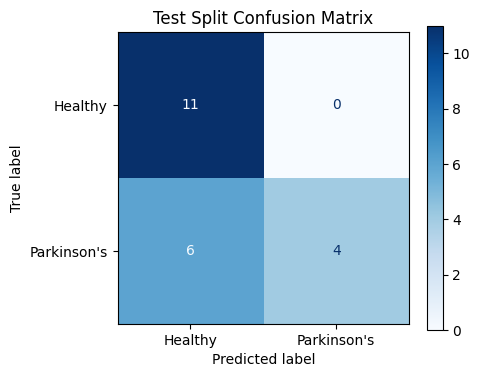

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Generate probabilities for the test split
rf_probs = rf_model.predict_proba(X_test)[:, 1]
gb_probs = gb_model.predict_proba(X_test)[:, 1]

# 2. Apply ensemble weights (0.4 RF + 0.6 GB) and the safe threshold
RF_W, GB_W = 0.4, 0.6
ensemble_probs = (RF_W * rf_probs) + (GB_W * gb_probs)
SAFE_THRESHOLD = 0.55  # You can adjust this to 0.82 if testing real-world local mic alignment

ensemble_preds = (ensemble_probs >= SAFE_THRESHOLD).astype(int)

# 3. Print Comprehensive Metrics
print("=" * 45)
print("TEST SPLIT ACCURACY REPORT (ENSEMBLE)")
print("=" * 45)
print(f"Standard Accuracy:     {accuracy_score(y_test, ensemble_preds):.4f}")
print(f"Balanced Accuracy:     {balanced_accuracy_score(y_test, ensemble_preds):.4f}")

print("\nDetailed Classification Report:")
print(classification_report(
    y_test,
    ensemble_preds,
    target_names=["Healthy", "Parkinson's"],
    zero_division=0
))

# 4. Plot Visual Confusion Matrix
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    ensemble_preds,
    display_labels=["Healthy", "Parkinson's"],
    ax=ax,
    cmap=plt.cm.Blues
)
plt.title("Test Split Confusion Matrix")
plt.tight_layout()
plt.show()